# Experiment: XAUUSD ML Bull / ML Bear (pybroker + LightGBM)

**คำถาม:** classifier 2 ตัวต่อ horizon จะบอกได้ไหมว่า "long จะชนะ" (ML Bull) และ "short จะชนะ" (ML Bear) ภายใต้กติกาเดียวกับระบบ trading ของ harness (SL 1R, TP 1.5R, time stop, `stop_first`)

**เกณฑ์ความสำเร็จ (บน test เปิดดูครั้งเดียว):** win rate 40–50% และ profit factor > 1 หลังหักต้นทุน ถ้าไม่ถึงจะรายงานตามจริง

| | |
|---|---|
| ข้อมูล | `data/XAU_{15m,1h,1d}_data.csv` (เวลา server ของ broker) |
| ช่วงที่ใช้ | **2025-01-01 → 2026-01-30 เท่านั้น** (ผู้ใช้กำหนด: ก่อน 2025 ราคาวิ่ง 10–20 pips ใช้หลายชั่วโมง เป็นคนละ regime) — แท่งก่อนหน้าใช้เป็น warm-up ของ indicator อย่างเดียว ไม่เป็นแถวเทรน |
| Split | train 2025-01 → 2025-07 · validation 2025-08 → 2025-09 · test 2025-10 → 2026-01-30 (purge/embargo = time stop) |
| ห้ามใช้ | Aug–Sep 2026 (เก็บไว้ทดสอบผ่าน backtest API ของ harness) — `data.load` assert ไว้ |
| Library | pybroker (indicator, model, walk-forward, backtest) + LightGBM (CPU) |
| โค้ดช่วย | `xau_ml/` (config, data, features, labels, model, sim, pb, predictor) — ไม่ถูก import จาก `backend/` |

**วิธีรัน:** ใช้ kernel จาก venv ของ notebook (ดู `requirements.txt`) และเปิด notebook จากโฟลเดอร์ `Product/notebook/` แล้ว Run All

# 📄 รายงาน: ML Bull / ML Bear สำหรับ XAUUSD

> **ผู้อ่าน:** ทีม harness / ผู้ตัดสินใจว่าจะต่อโมเดลเข้าระบบ trading หรือไม่ · **สถานะ:** research เท่านั้น ยังไม่ต่อ backend · **วันที่:** 2026-10-04 · **version:** `xau-bullbear-0.1.0`

## 1. บทสรุปผู้บริหาร

- เทรน classifier 2 ตัวต่อ horizon — **ML Bull** (long จะแตะ TP ก่อน SL ไหม) และ **ML Bear** (short) — บน XAUUSD ช่วง **2025-01 → 2026-01** ด้วยกติกาเดียวกับ simulator ของ harness
- บน test (2025-10-17 → 2026-01-30) **3 จาก 4 config ผ่านเป้าตามตัวเลข** (win rate 42.6–50%, PF 1.12–1.39) แต่ **ทุกตัวเป็น long 100% และแพ้ baseline always-long (PF 1.37) / buy & hold (+22.7%)** → ยังไม่มีหลักฐานว่าโมเดลมี skill เกินกว่า "ตลาดขาขึ้น"
- skill ด้าน ML: intraday มีบ้างแต่อ่อน (AUC bear 0.60, bull 0.56) · swing ไม่มี (AUC 0.47)
- **ข้อค้นพบที่มีประโยชน์ที่สุด:** always-short แพ้หนักที่สุดทุก horizon (intraday −65R, swing −20R) — ปี 2025 ทองอยู่เหนือ SMA50 และ SMA200 รายวัน 91% ของเวลา การที่ระบบ LLM short เกือบตลอดคือการสวนเทรนด์รายวันแทบทุกไม้
- **ข้อเสนอ:** ใช้เป็น **หลักฐานให้ analyst** (P_bull/P_bear + provenance) ไม่ใช่ policy gate; ถ้าจะทำ policy ให้เป็นระดับ warn จนกว่าจะผ่าน backtest Aug–Sep 2026

## 2. โจทย์และกติกา (ตรงกับระบบ trading ปัจจุบัน)

| | intraday | swing |
|---|---|---|
| แท่งหลัก | 15m | 1h |
| R (ระยะ stop) | 1.5 × ATR14(15m) | 2.0 × ATR14(1h) |
| time stop | 16 แท่งหลังแท่งเข้า | 48 แท่งหลังแท่งเข้า |
| บริบท | 1h + 1d | 1d |

- **Label แบบ triple-barrier:** เข้าที่ open แท่งถัดไป · Bull = 1 ถ้าแตะ entry + 1.5R ก่อน entry − 1R · Bear กลับกัน · แตะทั้งคู่ในแท่งเดียว = SL (`stop_first`) · open กระโดดเลยระดับ = ออกที่ open · หมดเวลา = 0
- **ชุด `ct25`:** TP = 2.5R เมื่อสวนเทรนด์รายวัน (close รายวันอยู่ฝั่งเดียวกันของทั้ง SMA50 และ SMA200 ตรงข้ามกับทิศเทรด) — ตรงกับ policy `counter_trend_risk_reward`
- **กฎสัญญาณ:** long เมื่อ P_bull ≥ τ และ P_bull − P_bear ≥ m · short กลับกัน · นอกนั้น flat · τ/m เลือกบน validation เท่านั้น
- **เทรด:** ทีละ position, เสี่ยง 1% ของ equity/ไม้, ต้นทุน 0.30 USD/oz ไป-กลับ

## 3. ข้อมูล

- ใช้เฉพาะ **2025-01-01 → 2026-01-30** (คำตัดสินของผู้ใช้: ก่อน 2025 ราคาวิ่ง 10–20 pips ใช้หลายชั่วโมง เป็นคนละ regime) — แท่งก่อนหน้าใช้เป็น warm-up ของ indicator เท่านั้น · Aug–Sep 2026 ห้ามใช้ (assert ใน `data.load`)
- **timezone:** เวลา server แบบ New-York-aligned (UTC+2 / UTC+3 ตาม DST ของสหรัฐฯ) — ยืนยันจากแท่ง NFP ที่ 15:30 server ทั้งปี
- **คุณภาพ:** ไม่มีแท่งซ้ำ, ไม่มีแท่งเสาร์–อาทิตย์, OHLC ถูกรูปทุกแท่ง, volume ไม่เป็น 0
- ⚠️ **ข้อมูลหาย 2 ช่วง:** 2025-09-12 → 10-15 (32 วัน, ราคากระโดด +13.8%) และ 2026-01-13 → 01-22 (9 วัน) → ไม่มี label/ไม่เข้าเทรดคร่อมช่วงนี้ และตัด 200 แท่งหลังช่วงออก

## 4. วิธีการ

| ขั้น | ทำอะไร | กันการโกงอย่างไร |
|---|---|---|
| Feature | 31 ตัวจากแท่งหลัก + บริบท 1h/1d (intraday 53, swing 44) ผ่าน `pybroker.indicator` | merge HTF บนเวลาปิดแท่ง; truncation test ตัดข้อมูลหลังเวลาตัดสินใจแล้วได้ค่าเท่าเดิม (diff = 0) |
| Split | train 2025-01→07 · val 2025-08→09 · test 2025-10→2026-01 | ไม่ shuffle; purge `time_stop+1` แถว, embargo `time_stop` แถว; assert ไม่มี label ทับข้าม split |
| Walk-forward | `Strategy.walkforward` 4 windows (ขยายเป็น expanding ใน train fn) | τ/m ตั้งไว้ก่อน ไม่ใช้เลือกอะไร |
| โมเดล | LightGBM ตื้น + early stopping บนท้ายของ train | validation ไม่ถูกใช้ตอน fit |
| Calibration | isotonic vs Platt เลือกด้วย cross-fit ใน validation | ไม่แตะ test |
| Test | เปิดครั้งเดียว ล็อกด้วย `models/test_lock.json` | ถ้า config เปลี่ยนหลังเปิด test → error |
| Backtest | pybroker + replica กติกา harness (`sim.py`) คู่กัน | ผลสองตัวใกล้กันมาก (ยืนยันกติกา) |

## 5. ผลลัพธ์ (test)

| config | τ / m | trades | win rate | PF | expectancy | max DD | long |
|---|---|---|---|---|---|---|---|
| intraday / base | ไม่เทรด | 0 | – | – | – | – | – |
| intraday / ct25 | 0.35 / 0 | 16 | 50.0% | 1.39 | +0.19R | 2.1% | 100% |
| swing / base | 0.45 / 0.20 | 68 | 42.6% | 1.12 | +0.06R | 5.1% | 100% |
| swing / ct25 | 0.45 / 0 | 74 | 46.0% | 1.28 | +0.15R | 5.0% | 100% |
| always-long (swing) | – | 81 | 48.1% | 1.37 | +0.18R | 5.5% | 100% |
| always-short (swing) | – | 88 | 33.0% | 0.66 | −0.23R | 20.3% | 0% |
| SMA20/50 cross (swing) | – | 20 | 55.0% | 1.81 | +0.37R | 3.0% | 50% |

(ตัวเลขจาก replica; pybroker ให้ผลใกล้เคียง — ดูตารางเต็มใน §9)

## 6. จุดอ่อนและความเสี่ยงของข้อสรุป

1. **regime เดียว** — 13 เดือนขาขึ้นแรง test ก็ขาขึ้น จึงรางวัล long-only
2. **ข้อมูลน้อย** — ช่วงข้อมูลหายทำให้ validation ของ swing มีแค่ ~13 หน้าต่างอิสระ, intraday/ct25 มี 16 เทรด (คลาดเคลื่อน ±0.3R)
3. **overfit** — AUC train 0.73–0.89 vs validation 0.55
4. **SHAP บอกว่าโมเดลเรียน regime** (ADX/ATR รายวัน, ชั่วโมง) ไม่ใช่จังหวะเข้า
5. **pybroker ไม่เช็ค stop ในแท่งเข้า** ต่างจาก harness เล็กน้อย
6. **ความโปร่งใส:** lock ของ test ถูกลบหนึ่งครั้งก่อนเปิดดูผล เพราะพบ data hole จาก audit

## 7. ข้อเสนอการต่อเข้า harness

- ❌ **policy gate (block):** ยังไม่ควร — skill ไม่ชัด และสิ่งที่โมเดลจับได้ (อย่า short ในขาขึ้น) rule deterministic ที่มีอยู่ทำได้ตรงกว่า
- ✅ **หลักฐานให้ analyst:** tool คำนวณ (F1) ที่โหลด `models/*.json` ผ่าน `xau_ml/predictor.py` คืน P_bull, P_bear, base rate และ break-even ของ R:R ที่เสนอ พร้อม provenance `kind=compute` (version + sha ของโมเดล)
- ⚠️ **policy ระดับ warn (ทางเลือก):** "ML P(win) ต่ำกว่า break-even ของ R:R ที่เสนอ" — ไม่ block
- ขั้นถัดไป: วัดผลจริงด้วย backtest API ช่วง Aug–Sep 2026, เพิ่มข้อมูล Feb–Jul 2026, ลอง meta-labeling บนข้อเสนอของ LLM

## 8. วิธีรันซ้ำและไฟล์ผลลัพธ์

- ติดตั้ง: ดู `requirements.txt` (venv นอก OneDrive, kernel `xau-ml`) → เปิด notebook จาก `Product/notebook/` → Run All (~3 นาที, deterministic)
- โค้ดช่วย: `xau_ml/` — `config` (ค่าคงที่ทั้งหมด), `data` (โหลด + ตรวจ), `features`, `labels`, `model` (split/fit/calibrate), `sim` (replica กติกา harness), `pb` (pybroker), `predictor` (save/load)
- ผลลัพธ์: `models/xau_<horizon>_<labels>.{bull,bear}.txt` (LightGBM text) + `.json` (features, label params, splits, τ/m, calibrator, metrics val/walk-forward/test) + `test_lock.json`

In [1]:
# Setup: imports and reproducibility
from __future__ import annotations

import dataclasses
import hashlib
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybroker as pyb
import shap
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

NB_DIR = Path.cwd()
assert (NB_DIR / "xau_ml").is_dir(), "เปิด notebook จาก Product/notebook/"
sys.path.insert(0, str(NB_DIR))
from xau_ml import config as C  # noqa: E402
from xau_ml import data as D  # noqa: E402
from xau_ml import features as F  # noqa: E402
from xau_ml import labels as L  # noqa: E402
from xau_ml import model as M  # noqa: E402
from xau_ml import pb as P  # noqa: E402
from xau_ml import predictor as PR  # noqa: E402
from xau_ml import sim as S  # noqa: E402

SEED = 42
np.random.seed(SEED)
pyb.disable_progress_bar()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)

# GPU: try LightGBM's GPU learner; the pip wheel is usually CPU-only, and ~20k rows train in seconds on CPU
try:
    _X = np.random.rand(2000, 5)
    lgb.train({"objective": "binary", "device_type": "gpu", "verbose": -1}, lgb.Dataset(_X, (_X[:, 0] > 0.5).astype(int)), 5)
    DEVICE = "gpu"
except Exception as e:  # noqa: BLE001
    DEVICE = "cpu"
    print("GPU not usable ->", str(e).splitlines()[0])
SIDES = ("bull", "bear")
print(f"python {sys.version.split()[0]} | pybroker {pyb.__version__} | lightgbm {lgb.__version__} | device={DEVICE}")

GPU not usable -> GPU Tree Learner was not enabled in this build.
python 3.12.10 | pybroker 2.0.1 | lightgbm 4.7.0 | device=cpu


## Plan

- **Hypothesis:** feature จากแท่งหลัก + บริบท 1h/1d มีข้อมูลพอให้ P(win) ของ long/short ต่างจาก base rate และกฎ τ/m ที่เลือกบน validation ให้ PF > 1 บน test
- **Configs (4 ชุด × 2 โมเดล):** horizon `intraday` (15m, SL 1.5×ATR, time stop 16) / `swing` (1h, SL 2.0×ATR, time stop 48) × label set `base` (TP 1.5R) / `ct25` (TP 2.5R เมื่อสวนเทรนด์รายวัน)
- **Sweep บน validation เท่านั้น:** calibrator (isotonic vs Platt), τ ∈ 0.30…0.70, m ∈ {0, .05, .10, .15, .20}
- **Metrics:** ML = ROC-AUC, Brier, calibration curve, precision@threshold · เทรด = trades, win rate, PF, expectancy (R), max DD, สัดส่วน long/short · baseline = buy & hold, always-short, always-long, SMA20/50 cross
- **วินัย test:** เซลล์ test สร้าง `models/test_lock.json` (hash ของโมเดล + τ/m) ถ้ารันซ้ำด้วย config ที่เปลี่ยนจะ error

In [2]:
# Fixed choices (xau_ml/config.py) — set before any model is fitted
display(pd.DataFrame([
    {"horizon": h.name, "bars": h.tf, "R (stop)": f"{h.sl_atr} x ATR14({h.tf})", "time_stop_bars": h.time_stop,
     "context": " + ".join(h.htf)} for h in C.HORIZONS.values()
]))
display(pd.DataFrame([
    {"label_set": s.name, "TP": f"{s.tp_r}R", "TP when counter-trend": f"{s.ct_tp_r}R" if s.ct_tp_r else "same"}
    for s in C.LABEL_SETS.values()
]))
display(pd.DataFrame({"start": [C.TRAIN[0], C.VAL[0], C.TEST[0]], "end": [C.TRAIN[1], C.VAL[1], C.TEST[1]]},
                     index=["train", "validation", "test"]))
print(f"cost {C.COST_PRICE} USD/oz round trip | risk {C.RISK_PCT:.0%} equity/trade | warm-up from {C.WARMUP_START}")

,horizon,bars,R (stop),time_stop_bars,context
0,intraday,15m,1.5 x ATR14(15m),16,1h + 1d
1,swing,1h,2.0 x ATR14(1h),48,1d


,label_set,TP,TP when counter-trend
0,base,1.5R,same
1,ct25,1.5R,2.5R


,start,end
train,2025-01-01,2025-07-31 23:59
validation,2025-08-01,2025-09-30 23:59
test,2025-10-01,2026-01-30 23:59


cost 0.3 USD/oz round trip | risk 1% equity/trade | warm-up from {'15m': '2024-10-01', '1h': '2024-06-01', '1d': '2023-06-01'}


## 1. ตรวจข้อมูลก่อนทำ feature

ตรวจ: แท่งซ้ำ, ลำดับเวลา, แท่งเสาร์–อาทิตย์, gap (สุดสัปดาห์ / พักรายวัน / วันหยุดหรือแท่งหาย), OHLC ไม่สอดคล้อง, volume = 0, ราคากระโดดผิดปกติ และ timezone

In [3]:
# Load: main + warm-up bars only (nothing at/after 2026-08-01 can load — asserted in data.load)
RAW = {tf: D.load(tf, C.WARMUP_START[tf]) for tf in ("15m", "1h", "1d")}
ALL = {tf: D.load(tf) for tf in ("15m", "1h", "1d")}  # full history, audit only
STUDY = {tf: r[r["date"] >= C.TRAIN[0]] for tf, r in RAW.items()}

audit = pd.DataFrame(
    {f"{tf} 2025-01..2026-01": D.quality_report(STUDY[tf], tf) for tf in STUDY}
    | {f"{tf} all 2004..2026": D.quality_report(ALL[tf], tf) for tf in ALL}
)
audit.loc["csv_duplicate_timestamps"] = [len(D.csv_duplicates(c.split()[0])) for c in audit.columns]
display(audit)

,15m 2025-01..2026-01,1h 2025-01..2026-01,1d 2025-01..2026-01,15m all 2004..2026,1h all 2004..2026,1d all 2004..2026
rows,22779,5705,251,494235,125206,5531
first,2025-01-02 01:00:00,2025-01-02 01:00:00,2025-01-02 00:00:00,2004-06-11 07:15:00,2004-06-11 07:00:00,2004-06-11 00:00:00
last,2026-01-30 23:45:00,2026-01-30 23:00:00,2026-01-30 00:00:00,2026-01-30 23:45:00,2026-01-30 23:00:00,2026-01-30 00:00:00
non_monotonic,0,0,0,0,0,0
weekend_bars(Sat/Sun),0,0,0,0,0,0
gaps_weekend,49,49,49,1067,1067,1067
gaps_daily_break,190,190,0,4292,4236,0
gaps_other(holiday/missing),18,14,5,3161,294,87
bars_missing_in_other_gaps,4652,1153,45,33753,7074,239
ohlc_inconsistent,0,0,0,0,0,0


**อ่านผล:** คอลัมน์ 2025-01..2026-01 คือช่วงที่ใช้จริง — ไม่มีแท่งซ้ำ/เสาร์–อาทิตย์/OHLC ผิดรูป/volume 0; `gaps_other` คือวันหยุด + ช่วงข้อมูลหาย (ดูเซลล์ถัดไป)

In [4]:
# Gaps that are neither weekend nor the daily 00:00-01:00 break, and z>8 price jumps (study window)
for tf in ("15m", "1h"):
    g = D.other_gaps(STUDY[tf], tf)
    g["missing_bars"] = (g["gap"] / C.TF_DELTA[tf] - 1).astype(int)
    print(f"{tf}: {len(g)} unusual gaps; largest:")
    display(g.sort_values("gap", ascending=False).head(6))
for tf in ("15m", "1h", "1d"):
    o = D.outliers(STUDY[tf])
    print(f"{tf}: {len(o)} bars with |log-return z| > 8")
    if len(o):
        display(o[["date", "open", "high", "low", "close", "volume", "logret", "z"]].head(8))

15m: 18 unusual gaps; largest:


,date,prev,gap,missing_bars
13,2025-10-15 07:45:00,2025-09-12 23:45:00,32 days 08:00:00,3103
17,2026-01-22 18:45:00,2026-01-13 14:15:00,9 days 04:30:00,881
4,2025-04-21 01:00:00,2025-04-17 23:45:00,3 days 01:15:00,292
15,2025-12-26 01:00:00,2025-12-24 20:30:00,1 days 04:30:00,113
16,2026-01-02 01:00:00,2025-12-31 23:45:00,1 days 01:15:00,100
9,2025-07-03 12:00:00,2025-07-03 03:00:00,0 days 09:00:00,35


1h: 14 unusual gaps; largest:


,date,prev,gap,missing_bars
9,2025-10-15 07:00:00,2025-09-12 23:00:00,32 days 08:00:00,775
13,2026-01-22 18:00:00,2026-01-13 14:00:00,9 days 04:00:00,219
3,2025-04-21 01:00:00,2025-04-17 23:00:00,3 days 02:00:00,73
11,2025-12-26 01:00:00,2025-12-24 20:00:00,1 days 05:00:00,28
12,2026-01-02 01:00:00,2025-12-31 23:00:00,1 days 02:00:00,25
6,2025-07-03 12:00:00,2025-07-03 03:00:00,0 days 09:00:00,8


15m: 11 bars with |log-return z| > 8


,date,open,high,low,close,volume,logret,z
6190,2025-01-06 15:30:00,2642.3900,2642.5200,2624.3400,2624.7500,1597.0000,-0.0067,-8.1496
8514,2025-02-11 04:30:00,2939.9500,2941.5400,2906.3100,2916.3900,1865.0000,-0.0080,-8.9156
13090,2025-04-23 01:00:00,3347.9900,3347.9900,3312.8900,3335.3900,1966.0000,-0.0136,-8.2649
17780,2025-07-03 15:30:00,3349.6600,3349.6700,3311.6900,3312.2800,1548.0000,-0.0112,-11.0141
19671,2025-08-01 15:30:00,3300.8600,3340.5800,3300.8600,3339.2100,1535.0000,0.0115,12.5381
21057,2025-08-22 17:00:00,3335.4500,3361.1100,3335.2700,3358.9900,1448.0000,0.0076,11.0584
21961,2025-09-05 15:30:00,3554.7100,3586.8100,3554.3300,3583.7300,1668.0000,0.0082,8.5603
22455,2025-10-15 07:45:00,4178.8500,4179.7000,4178.6600,4179.6900,111.0000,0.1376,22.0561


1h: 4 bars with |log-return z| > 8


,date,open,high,low,close,volume,logret,z
4998,2025-04-07 04:00:00,2978.2900,3055.0100,2971.7600,3038.0900,7396.0000,0.0197,8.5629
7594,2025-10-15 07:00:00,4178.8500,4179.7000,4178.6600,4179.6900,111.0000,0.1376,21.5912
9021,2026-01-22 18:00:00,4882.2300,4883.4300,4874.4200,4877.9500,4397.0000,0.0621,16.0434
9135,2026-01-29 17:00:00,5497.3300,5497.6000,5097.3800,5182.6700,406226.0000,-0.0589,-12.0056


1d: 1 bars with |log-return z| > 8


,date,open,high,low,close,volume,logret,z
591,2025-10-15,4178.8500,4218.1200,4163.6200,4207.4500,513511.0000,0.1442,9.2830


**อ่านผล:** gap 32 วัน (2025-09-12 → 10-15) และ 9 วัน (2026-01-13 → 01-22) คือ **ข้อมูลหาย** ไม่ใช่ตลาดปิด — แท่งแรกหลัง gap มี z = 22 เพราะราคาวิ่งไป +13.8% ระหว่างนั้น; แท่ง |z| > 8 อื่นเป็นข่าวจริง (NFP 15:30, tariff 2025-04-07, ทองร่วง 2026-01-29) จึงเก็บไว้

In [5]:
# Timezone. 1) session shape: hours present per server hour (15m bars, study window)
hours = STUDY["15m"]["date"].dt.hour.value_counts().sort_index()
print("15m bars per server hour:", hours.to_dict())
# 2) US payrolls (08:30 New York) → which server bar spikes? constant server time across US DST = NY-aligned clock
nfp = D.nfp_server_times(ALL["15m"], "2024-01-01", "2026-01-31")
display(nfp)
print("server - UTC (hours) by month:", nfp.groupby(pd.to_datetime(nfp["day"]).dt.month)["server_minus_utc_h"].median().to_dict())
# 3) does the 1d file use the same server-day boundary as the 15m file?
rs = D.resample_daily(STUDY["15m"]).join(STUDY["1d"].set_index("date")[["open", "high", "low", "close"]], rsuffix="_1d", how="inner")
for k in ("open", "high", "low", "close"):
    print(f"daily {k}: |15m-resampled − 1d| median {np.median(np.abs(rs[k] - rs[k + '_1d'])):.3f}, share within $0.5: {(np.abs(rs[k] - rs[k + '_1d']) < 0.5).mean():.1%}")

15m bars per server hour: {0: 80, 1: 996, 2: 996, 3: 993, 4: 986, 5: 984, 6: 984, 7: 989, 8: 992, 9: 992, 10: 995, 11: 993, 12: 1000, 13: 1000, 14: 997, 15: 996, 16: 994, 17: 994, 18: 997, 19: 1000, 20: 995, 21: 979, 22: 963, 23: 884}


,day,max_range_bar_server,nfp_utc,server_minus_utc_h,range_x_median
0,2024-01-05,17:00,13:30,3.5000,7.4112
1,2024-02-02,15:30,13:30,2.0000,8.7840
2,2024-03-01,17:00,13:30,3.5000,3.6238
3,2024-04-05,15:30,12:30,3.0000,3.0581
4,2024-05-03,16:30,12:30,4.0000,8.5411
5,2024-06-07,15:30,12:30,3.0000,2.0126
6,2024-07-05,15:30,12:30,3.0000,8.2292
7,2024-08-02,17:30,12:30,5.0000,8.6093
8,2024-09-06,15:30,12:30,3.0000,6.2811
9,2024-10-04,15:30,12:30,3.0000,7.2457


server - UTC (hours) by month: {1: 1.75, 2: 2.0, 3: 2.75, 4: 3.0, 5: 3.875, 6: 3.0, 7: 1.5, 8: 4.0, 9: 3.0, 10: 3.0, 11: 3.5, 12: 3.375}
daily open: |15m-resampled − 1d| median 0.000, share within $0.5: 100.0%
daily high: |15m-resampled − 1d| median 0.000, share within $0.5: 100.0%
daily low: |15m-resampled − 1d| median 0.000, share within $0.5: 100.0%
daily close: |15m-resampled − 1d| median 0.000, share within $0.5: 100.0%


**อ่านผล:** แท่งที่ผันผวนสุดวัน NFP ตกที่ 15:30 server เกือบทุกเดือน ทั้งตอน NFP = 13:30 UTC (ฤดูหนาว) และ 12:30 UTC (ฤดูร้อน) → นาฬิกา server ขยับตาม DST ของนิวยอร์ก = UTC+2/+3; daily bar ตรงกับ 15m ที่ resample เป็นวัน server

### สรุปผลตรวจข้อมูล (2025-01 → 2026-01)

- **Timezone:** เวลา server ของ broker แบบ **New-York-aligned (UTC+2 ฤดูหนาว / UTC+3 ฤดูร้อนของสหรัฐฯ)** — แท่ง NFP (08:30 NY) ตกที่ **15:30 server** แทบทุกเดือนทั้งช่วงที่ US ใช้/ไม่ใช้ DST, ตลาดพักรายวัน 00:00–01:00 server (ชั่วโมง 0 มีแท่งน้อยมาก) และแท่ง 1d = วัน server เดียวกับ 15m (resample ตรงกัน) → feature `hour` คือชั่วโมง server ไม่ใช่ UTC
- **แท่งซ้ำ / ลำดับเวลา / OHLC ผิดรูป / volume 0 / แท่งเสาร์–อาทิตย์:** ไม่มีเลย (ทั้งช่วงศึกษาและทั้งไฟล์ 2004–2026)
- **Gap ปกติ:** สุดสัปดาห์ (ศุกร์ 23:45 → จันทร์ 01:00) และพักรายวัน, วันหยุด (Good Friday 2025-04-18, คริสต์มาส, ปีใหม่, 4 ก.ค.)
- ⚠️ **ข้อมูลหาย 2 ช่วงใหญ่ (ไม่ใช่วันหยุดตลาด):** **2025-09-12 23:45 → 2025-10-15 07:45 (32 วัน, 15m หาย 3,103 แท่ง)** ราคากระโดด +13.8% ข้าม hole และ **2026-01-13 → 2026-01-22 (9 วัน)** → จัดการโดย (1) ไม่มี label/ไม่เข้าเทรด ถ้าหน้าต่างเทรดคร่อม hole (2) ตัด 200 แท่งหลัง hole ออกจาก train/eval เพราะ feature คร่อมข้อมูลที่หาย (คอลัมน์ `no_entry`, `labels.data_holes`) — ผลคือ **test จริงเริ่ม ~2025-10-17 และ validation จบ 2025-09-12**
- **ราคาผิดปกติ (|z| > 8):** ส่วนใหญ่เป็นข่าวจริง (NFP 15:30, 2025-04-07 tariff shock, 2026-01-29/30 ทองร่วง ~$900) ยกเว้นแท่งแรกหลัง hole — ไม่ได้ลบแท่งข่าวจริงเพราะระบบจริงก็เจอ

## 2. Features (ห้าม look-ahead)

- **แท่งหลัก** (`features.BASE_FEATURES`): log/ATR returns หลายช่วง, ATR%/regime/realized vol, RSI14 + การเปลี่ยน, MACD/hist ÷ ATR, Bollinger %B + ความกว้าง, ระยะจาก SMA20/50/200 ÷ ATR + slope, ตำแหน่งในกรอบ 16/48/96 แท่ง, volume ÷ ค่าเฉลี่ย 48, body/wick ÷ ATR, ADX/DI, การขยับตั้งแต่ต้นวัน, ชั่วโมง, วันในสัปดาห์
- **timeframe ใหญ่กว่า:** 1h→15m และ 1d→ทั้งคู่ ผ่าน `merge_asof(backward)` บน **เวลาปิดแท่ง** (`t_close`) เทียบกับเวลาปิดของแท่งหลัก (= เวลาตัดสินใจ) → ได้เฉพาะแท่งที่ปิดแล้ว
- สูตร Wilder/RSI/MACD/Bollinger ตรงกับ `backend/app/domain/compute/indicators.py`
- **การพิสูจน์ว่าไม่ look-ahead:** (1) เวลาปิดของ HTF ≤ เวลาตัดสินใจทุกแถว (2) **truncation test** สร้าง feature ใหม่จากข้อมูลที่ตัดทิ้งทุกอย่างหลังเวลาตัดสินใจ แล้วต้องได้ค่าเท่าเดิมเป๊ะ (3) ไม่มีคอลัมน์ label อยู่ใน feature (4) ค่าที่ pybroker คำนวณเองต้องตรงกับ pandas (ทำใน §5)

In [6]:
FRAMES = {}
for hz in C.HORIZONS.values():
    FRAMES[hz.name] = F.build(RAW[hz.tf], hz.tf, {tf: RAW[tf] for tf in hz.htf})
FEATURES = {k: F.feature_columns(v) for k, v in FRAMES.items()}
for k, cols in FEATURES.items():
    study = FRAMES[k][FRAMES[k]["date"] >= C.TRAIN[0]]
    print(f"{k}: {len(cols)} features, {len(study):,} rows in 2025-01..2026-01, NaN share in study rows = {study[cols].isna().mean().max():.4f}")
print(FEATURES["intraday"])

intraday: 53 features, 22,779 rows in 2025-01..2026-01, NaN share in study rows = 0.0000
swing: 44 features, 5,705 rows in 2025-01..2026-01, NaN share in study rows = 0.0000
['logret_1', 'ret_atr_4', 'ret_atr_16', 'ret_atr_48', 'atr_pct', 'atr_regime', 'rv_32', 'rsi14', 'rsi14_chg4', 'macd_atr', 'macd_hist_atr', 'macd_hist_chg', 'bb_pctb', 'bb_width', 'dist_sma20_atr', 'dist_sma50_atr', 'dist_sma200_atr', 'sma20_slope_atr', 'sma50_slope_atr', 'range_pos_16', 'range_pos_48', 'range_pos_96', 'vol_ratio_48', 'body_atr', 'upper_wick_atr', 'lower_wick_atr', 'adx14', 'di_diff', 'day_move_atr', 'hour', 'dow', 'h1_rsi14', 'h1_adx14', 'h1_di_diff', 'h1_dist_sma50_atr', 'h1_dist_sma200_atr', 'h1_macd_hist_atr', 'h1_ret_atr_5', 'h1_range_pos_20', 'h1_atr_pct', 'd1_rsi14', 'd1_adx14', 'd1_di_diff', 'd1_dist_sma50_atr', 'd1_dist_sma200_atr', 'd1_macd_hist_atr', 'd1_ret_atr_5', 'd1_range_pos_20', 'd1_atr_pct', 'd1_above_sma50', 'd1_above_sma200', 'd1_trend', 'd1_prev_range_pos']


In [7]:
# Look-ahead assertions
rng = np.random.default_rng(SEED)
for hz in C.HORIZONS.values():
    fr, cols = FRAMES[hz.name], FEATURES[hz.name]
    # (1) every merged higher-timeframe bar had closed by the decision time
    for tc in ("h1_t_close", "d1_t_close"):
        if tc in fr:
            assert (fr[tc] <= fr["t_close"]).all(), f"{hz.name}: {tc} after decision time"
    # (2) truncation: rebuild from data that ends at the decision time → identical features
    idx = rng.choice(np.flatnonzero(fr["date"] >= C.TRAIN[0]), 40, replace=False)
    worst = 0.0
    for t in idx:
        row = fr.iloc[t]
        main_cut = RAW[hz.tf][RAW[hz.tf]["date"] <= row["date"]]
        htf_cut = {tf: RAW[tf][RAW[tf]["t_close"] <= row["t_close"]] for tf in hz.htf}
        again = F.build(main_cut, hz.tf, htf_cut).iloc[-1]
        assert again["date"] == row["date"]
        a, b = row[cols].to_numpy(float), again[cols].to_numpy(float)
        assert np.array_equal(np.isnan(a), np.isnan(b)), (hz.name, row["date"])
        worst = max(worst, float(np.nanmax(np.abs(a - b))))
    assert worst < 1e-9, (hz.name, worst)
    # (3) nothing derived from the future is an input
    assert not [c for c in cols if c.startswith(F.LABEL_PREFIXES)]
    print(f"{hz.name}: HTF close ≤ decision time ✓ | truncation test on 40 rows, max |diff| = {worst:.1e} ✓ | no label columns ✓")

intraday: HTF close ≤ decision time ✓ | truncation test on 40 rows, max |diff| = 0.0e+00 ✓ | no label columns ✓


swing: HTF close ≤ decision time ✓ | truncation test on 40 rows, max |diff| = 0.0e+00 ✓ | no label columns ✓


**อ่านผล:** ทุกข้อผ่าน — สร้าง feature ใหม่จากข้อมูลที่ตัดทุกอย่างหลังเวลาตัดสินใจได้ค่าเท่าเดิมทุกตัว (diff = 0) จึงมั่นใจได้ว่าไม่มี look-ahead

## 3. Labels: triple-barrier ตามกติกาของ simulator

เข้าที่ `open` ของแท่งถัดไป (แท่งเข้า = `bars_held 0`), R = SL×ATR14 ของแท่งตัดสินใจ, ต่อแท่งตามลำดับของ `engine.py`: (1) แท่งหลังแท่งเข้า ถ้า open เลย SL/TP แล้ว → ออกที่ open (gap) (2) high/low แตะ SL หรือ TP — แตะทั้งคู่ในแท่งเดียว = **SL** (`stop_first`) (3) ครบ time stop แท่ง → ออกที่ close, label = 0

- **Bull** = 1 ถ้าแตะ entry + TP ก่อน entry − 1R · **Bear** = 1 ถ้าแตะ entry − TP ก่อน entry + 1R
- `ct25`: TP = 2.5R เมื่อเทรดสวนเทรนด์รายวัน (close รายวันล่าสุดที่ปิดแล้วอยู่ฝั่งเดียวกันของทั้ง SMA50 และ SMA200 ตรงข้ามกับทิศเทรด — ตรงกับ `_counter_trend` ใน workflows/trading.py) นอกนั้น 1.5R
- เก็บ `r_*` (R ที่ได้จริงก่อนหักต้นทุน) และ `exit_*` (จำนวนแท่ง) ไว้ใช้ใน simulator

In [8]:
LAB = {}
for hz in C.HORIZONS.values():
    for ls in C.LABEL_SETS.values():
        LAB[(hz.name, ls.name)] = L.add_labels(FRAMES[hz.name], hz, ls)

# spot-check the numba barrier against a slow, obviously-correct loop
for (hzn, lsn), fr in LAB.items():
    hz = C.HORIZONS[hzn]
    for t in rng.choice(np.flatnonzero((fr["date"] >= C.TRAIN[0]) & fr["y_bull"].notna()), 150, replace=False):
        for side, nm in ((1, "bull"), (-1, "bear")):
            ref = L.reference_label(fr, t, hz, fr[f"tp_{nm}"].iat[t], side)
            got = (fr[f"y_{nm}"].iat[t], fr[f"r_{nm}"].iat[t], fr[f"exit_{nm}"].iat[t])
            assert ref[0] == got[0] and abs(ref[1] - got[1]) < 1e-9 and ref[2] == got[2], (hzn, lsn, t, nm, ref, got)
print("labels == reference loop on 150 random rows x 2 sides x 4 configs ✓")

rows = []
for (hzn, lsn), fr in LAB.items():
    st = fr[(fr["date"] >= C.TRAIN[0]) & fr["y_bull"].notna()]
    for nm in SIDES:
        tp = st[f"tp_{nm}"]
        rows.append({"horizon": hzn, "labels": lsn, "side": nm, "rows": len(st), "win_rate(label=1)": st[f"y_{nm}"].mean(),
                     "share_TP_2.5R": (tp == 2.5).mean(), "breakeven_win_rate": (1 / (1 + tp)).mean(),
                     "mean_R_if_always_taken": st[f"r_{nm}"].mean()})
display(pd.DataFrame(rows))
for (hzn, lsn), fr in LAB.items():
    if lsn == "base":
        holes = fr.loc[fr["date"].diff() > L.HOLE, "date"]
        print(f"{hzn}: data holes > 4 days start at {[str(d) for d in holes]}; rows blocked (no label/entry or feature window over a hole): {int(fr['no_entry'].sum())}")
trend = LAB[("intraday", "base")].query("date >= @C.TRAIN[0]")["d1_trend"].value_counts(normalize=True).rename("share")
print("daily trend (close vs SMA50 & SMA200) over the study window:", trend.round(3).to_dict())

labels == reference loop on 150 random rows x 2 sides x 4 configs ✓


,horizon,labels,side,rows,win_rate(label=1),share_TP_2.5R,breakeven_win_rate,mean_R_if_always_taken
0,intraday,base,bull,22728,0.3235,0.0000,0.4000,0.0468
1,intraday,base,bear,22728,0.3070,0.0000,0.4000,-0.0461
2,intraday,ct25,bull,22728,0.3235,0.0000,0.4000,0.0468
3,intraday,ct25,bear,22728,0.1709,0.9076,0.2963,-0.0392
4,swing,base,bull,5558,0.4530,0.0000,0.4000,0.1754
5,swing,base,bear,5558,0.3329,0.0000,0.4000,-0.1373
6,swing,ct25,bull,5558,0.4530,0.0000,0.4000,0.1754
7,swing,ct25,bear,5558,0.1826,0.9054,0.2965,-0.2216


intraday: data holes > 4 days start at ['2025-10-15 07:45:00', '2026-01-22 18:45:00']; rows blocked (no label/entry or feature window over a hole): 434
swing: data holes > 4 days start at ['2025-10-15 07:00:00', '2026-01-22 18:00:00']; rows blocked (no label/entry or feature window over a hole): 442


daily trend (close vs SMA50 & SMA200) over the study window: {1.0: 0.908, 0.0: 0.092}


**อ่านผล:** break-even ของ 1.5R คือ win rate 40% — label = 1 แค่ ~31–32% (intraday) จึงต้องเลือกจังหวะถึงจะมีกำไร; swing bull ชนะ 45% เพราะตลาดขาขึ้น (เข้า long ทุกแท่ง = +0.18R) ส่วน bear ติดลบ; ใน `ct25` short 91% เป็นการสวนเทรนด์ (TP 2.5R) เพราะไม่มีวันไหนที่ราคาอยู่ใต้ทั้ง SMA50 และ SMA200

## 4. Split ตามเวลา + purge / embargo

- **purge:** ตัด `time_stop + 1` แถวสุดท้ายของ train และ validation (หน้าต่าง label ของแถวเหล่านี้ล้ำเข้า split ถัดไป)
- **embargo:** ตัด `time_stop` แถวแรกของ validation และ test
- ไม่ shuffle · โมเดลต้นไม้ไม่ต้องใช้ scaler · calibration fit บน validation เท่านั้น

In [9]:
MASKS = {}
rows = []
for key, fr in LAB.items():
    hz = C.HORIZONS[key[0]]
    MASKS[key] = mk = M.split_masks(fr, hz)
    M.assert_disjoint(fr, mk, hz)
    if key[1] == "base":
        for name, m in mk.items():
            d = fr.loc[m, "date"]
            rows.append({"horizon": key[0], "split": name, "rows": int(m.sum()), "from": d.min(), "to": d.max(),
                         "bull=1": fr.loc[m, "y_bull"].mean(), "bear=1": fr.loc[m, "y_bear"].mean()})
display(pd.DataFrame(rows))
print("no label window of an earlier split touches a later split ✓")

,horizon,split,rows,from,to,bull=1,bear=1
0,intraday,train,13648,2025-01-02 01:00:00,2025-07-31 19:30:00,0.3296,0.3077
1,intraday,val,2809,2025-08-01 05:00:00,2025-09-12 19:30:00,0.3090,0.2933
2,intraday,test,5838,2025-10-17 11:45:00,2026-01-30 19:30:00,0.3164,0.3123
3,swing,train,3374,2025-01-02 01:00:00,2025-07-29 20:00:00,0.4446,0.3595
4,swing,val,614,2025-08-05 03:00:00,2025-09-10 20:00:00,0.4609,0.2590
5,swing,test,1178,2025-10-27 22:00:00,2026-01-09 11:00:00,0.4643,0.2818


no label window of an earlier split touches a later split ✓


**อ่านผล:** หลังตัดช่วงข้อมูลหาย validation จบ 2025-09-12 และ test เริ่ม 2025-10-17 (intraday) / 10-27 (swing) — swing test จบ 2026-01-09 เพราะ 200 แท่งหลัง hole 01-22 ถูกตัด

## 5. Walk-forward (expanding) ใน pybroker — ช่วง train + validation

- feature ของแท่งหลักลงทะเบียนเป็น `pybroker.indicator` (ฟังก์ชันเดียวกับ predictor) และบริบท 1h/1d เป็น custom columns
- `Strategy.walkforward(windows=4, train_size=0.5, lookahead=time_stop+1)` — split ของ pybroker เป็นแบบ rolling ส่วน `pb.wf_train_fn` ขยายเป็น **expanding** (เทรนทุกแถวตั้งแต่ 2025-01-01 ถึงแท่ง train สุดท้ายของ window) แล้ว purge `time_stop+1` แถวท้าย ส่วน calibration (Platt) ใช้ 25% ท้ายของ train ใน window นั้น
- τ = 0.45, m = 0.05 **กำหนดไว้ก่อน** (เหนือ break-even 40% ของ 1.5R) — ส่วนนี้เป็นการวัดความเสถียร ไม่ได้ใช้เลือกอะไร
- เทรดด้วยกติการะบบ: เข้าที่ open แท่งถัดไป, stop 1R, target 1.5R (2.5R ถ้าสวนเทรนด์ใน `ct25`), `hold_bars` = time stop ออกที่ close, ทีละ position, เสี่ยง 1%/เทรด, ต้นทุน 0.30 USD/oz

In [10]:
INDS = P.register_indicators()
SMA_INDS = P.sma_indicators()
ALL_HTF = sorted({c for cols in FEATURES.values() for c in cols if c.startswith(("h1_", "d1_"))})


def use_columns(cols):
    """pybroker custom columns are global: register exactly the ones this frame carries."""
    for c in ALL_HTF:
        try:
            pyb.unregister_columns(c)
        except Exception:  # noqa: BLE001
            pass
    try:
        pyb.unregister_columns("no_entry")
    except Exception:  # noqa: BLE001
        pass
    pyb.register_columns(*cols, "no_entry")


def htf_cols(hzn):
    return [c for c in FEATURES[hzn] if c.startswith(("h1_", "d1_"))]


WF_TAU, WF_M, WF_WINDOWS = 0.45, 0.05, 4
WF, WF_LOG = {}, []
for (hzn, lsn), fr in LAB.items():
    hz, ls, cols = C.HORIZONS[hzn], C.LABEL_SETS[lsn], FEATURES[hzn]
    use_columns(htf_cols(hzn))
    names = {s: f"wf_{hzn}_{lsn}_{s}" for s in SIDES}
    log = []
    srcs = [P.register_wf_model(names[s], INDS, frame=fr, side=s, hz=hz, cols=cols, log=log) for s in SIDES]
    st = pyb.Strategy(P.pb_frame(fr, htf_cols(hzn)), C.WARMUP_START[hz.tf], C.VAL[1],
                      dataclasses.replace(P.config(hz.tf), return_signals=True))
    st.add_execution(P.model_exec(hz, ls, names["bull"], names["bear"], WF_TAU, WF_M), [C.SYMBOL], models=srcs, indicators=INDS)
    res = st.walkforward(windows=WF_WINDOWS, train_size=0.5, lookahead=hz.time_stop + 1,
                         start_date=C.TRAIN[0], end_date=C.VAL[1], timeframe=hz.tf)
    sig = res.signals[C.SYMBOL].set_index("date")
    ref = fr.set_index("date").loc[sig.index]
    # pybroker computed the base features itself — they must equal the pandas features
    # (float noise from a different summation order is allowed: relative 1e-7)
    for c in [c for c in F.BASE_FEATURES if c in sig]:
        a, b = sig[c].to_numpy(float), ref[c].to_numpy(float)
        assert np.allclose(a, b, rtol=1e-7, atol=1e-9, equal_nan=True), (c, np.nanmax(np.abs(a - b)))
    oos = {}
    for s in SIDES:
        col = f"{names[s]}_pred"  # pybroker stores model predictions as "<model>_pred"
        p = sig[col].to_numpy(float)
        ok = ~np.isnan(p) & ref[f"y_{s}"].notna().to_numpy()
        oos[s] = roc_auc_score(ref[f"y_{s}"].to_numpy()[ok], p[ok]) if ok.sum() > 100 else np.nan
    trades = P.trades_in_r(res, fr)
    WF[(hzn, lsn)] = {"oos_auc_bull": oos["bull"], "oos_auc_bear": oos["bear"], **P.r_metrics(trades, res)}
    WF_LOG += [{"horizon": hzn, "labels": lsn, **r} for r in log]

print("pybroker indicators == pandas features ✓ (all configs)")
display(pd.DataFrame(WF_LOG).query("labels == 'base' and side == 'bull'")[["horizon", "train_from", "train_to", "rows", "test_from", "test_to", "rounds"]])
display(pd.DataFrame(WF).T)

Backtesting: 2025-01-01 00:00:00 to 2025-09-30 23:59:00



Computing indicators...


Train split: 2025-01-02 13:45:00 to 2025-02-21 16:00:00


Finished training models:

 0:00:00 



...

Test split: 2025-07-28 17:00:00 to 2025-09-12 23:00:00


Finished backtest: 0:00:01


pybroker indicators == pandas features ✓ (all configs)


,horizon,train_from,train_to,rows,test_from,test_to,rounds
1,intraday,2025-01-02 01:00:00,2025-02-21 11:45:00,3322,2025-02-21 20:15:00,2025-04-14 14:00:00,20
3,intraday,2025-01-02 01:00:00,2025-04-14 05:45:00,6610,2025-04-14 14:15:00,2025-06-04 11:45:00,65
5,intraday,2025-01-02 01:00:00,2025-06-04 03:30:00,9898,2025-06-04 12:00:00,2025-07-25 04:15:00,20
7,intraday,2025-01-02 01:00:00,2025-07-24 19:00:00,13186,2025-07-25 04:30:00,2025-09-12 23:45:00,20
17,swing,2025-01-02 01:00:00,2025-02-25 21:00:00,889,2025-03-04 04:00:00,2025-04-22 08:00:00,103
19,swing,2025-01-02 01:00:00,2025-04-15 03:00:00,1676,2025-04-22 09:00:00,2025-06-09 15:00:00,20
21,swing,2025-01-02 01:00:00,2025-06-03 10:00:00,2463,2025-06-09 16:00:00,2025-07-28 16:00:00,67
23,swing,2025-01-02 01:00:00,2025-07-22 11:00:00,3250,2025-07-28 17:00:00,2025-09-12 23:00:00,20


oos_auc_bull  oos_auc_bear   trades  win_rate  profit_factor  expectancy_r  total_r  max_dd_pct  return_pct  long_share    longs   shorts
intraday base        0.5036        0.5659 307.0000    0.3518         0.7280       -0.1799 -55.2234     46.8650    -43.7278      0.4430 136.0000 171.0000
         ct25        0.5036        0.5748 187.0000    0.3797         0.8881       -0.0706 -13.2003     23.8239    -13.7536      0.8182 153.0000  34.0000
swing    base        0.4270        0.4867 147.0000    0.4082         0.9545       -0.0274  -4.0271     10.2778     -4.9643      0.5918  87.0000  60.0000
         ct25        0.4270        0.5167 112.0000    0.4286         1.1429        0.0829   9.2828      8.4995      8.6946      0.7679  86.0000  26.0000

**อ่านผล:** ค่า indicator ที่ pybroker คำนวณเองตรงกับ pandas ทุกตัว; OOS AUC ใกล้ 0.5 (bull) และ ~0.57 (bear intraday) → walk-forward ด้วย τ = 0.45 ที่ตั้งไว้ก่อน ขาดทุนเกือบทุก config (ต้นทุนกิน intraday ที่เทรดถี่)

## 6. โมเดลสุดท้าย: fit บน train → calibrate บน validation

- LightGBM (`config.ModelParams`: ต้นไม้ตื้น, `min_child_samples` สูง, L2) — early stopping ใช้ 20% ท้ายของ **train** (purge แล้ว) แล้ว refit ทั้ง train ด้วยจำนวนรอบนั้น → validation ไม่ถูกใช้ตอน fit
- calibrator: เลือก isotonic vs Platt ด้วย cross-fit 2 ส่วนตามเวลา **ภายใน validation** แล้ว fit ตัวที่ชนะบน validation ทั้งหมด
- Brier/AUC ของ validation หลัง calibrate เป็นค่า in-sample ของ calibrator (มองโลกในแง่ดี) — ตัวเลขที่เชื่อได้คือ `brier_crossfit` และผลบน test

In [11]:
FINAL, rows = {}, []
for key, fr in LAB.items():
    hz, cols, mk = C.HORIZONS[key[0]], FEATURES[key[0]], MASKS[key]
    tr, va = fr[mk["train"]], fr[mk["val"]]
    out = {"boosters": {}, "cals": {}, "p_val": {}}
    for s in SIDES:
        b = M.fit_lgbm(tr[cols], tr[f"y_{s}"].to_numpy(), hz, C.ModelParams(), DEVICE)
        y_va = va[f"y_{s}"].to_numpy()
        raw = b.predict(va[cols])
        cal, tab = M.choose_calibrator(raw, y_va)
        out["boosters"][s], out["cals"][s], out["p_val"][s] = b, cal, cal(raw)
        cf = tab.set_index("kind")["brier_crossfit"]
        rows.append({"horizon": key[0], "labels": key[1], "side": s, "rounds": b.num_trees(),
                     "auc_train": roc_auc_score(tr[f"y_{s}"], b.predict(tr[cols])), "auc_val": roc_auc_score(y_va, raw),
                     "base_rate_val": y_va.mean(), "brier_val_raw": brier_score_loss(y_va, raw),
                     "brier_val_climatology": brier_score_loss(y_va, np.full(len(y_va), tr[f"y_{s}"].mean())),
                     "brier_crossfit_iso": cf["isotonic"], "brier_crossfit_platt": cf["platt"], "calibrator": cal.kind})
    FINAL[key] = out
VAL_ML = pd.DataFrame(rows)
display(VAL_ML)

,horizon,labels,side,rounds,auc_train,auc_val,base_rate_val,brier_val_raw,brier_val_climatology,brier_crossfit_iso,brier_crossfit_platt,calibrator
0,intraday,base,bull,20,0.7324,0.5524,0.3090,0.2134,0.2139,0.2157,0.2143,platt
1,intraday,base,bear,45,0.7796,0.5812,0.2933,0.2042,0.2075,0.2219,0.2191,platt
2,intraday,ct25,bull,20,0.7324,0.5524,0.3090,0.2134,0.2139,0.2157,0.2143,platt
3,intraday,ct25,bear,75,0.8727,0.5561,0.1695,0.1480,0.1408,0.1550,0.1541,platt
4,swing,base,bull,20,0.8592,0.3423,0.4609,0.2676,0.2487,0.5624,0.4169,platt
5,swing,base,bear,20,0.8543,0.4246,0.2590,0.2063,0.2020,0.2952,0.2611,platt
6,swing,ct25,bull,20,0.8592,0.3423,0.4609,0.2676,0.2487,0.5624,0.4169,platt
7,swing,ct25,bear,20,0.8868,0.4532,0.1775,0.1506,0.1471,0.2096,0.2102,isotonic


**อ่านผล:** AUC train สูงกว่า validation มาก = overfit (label ทับกันทำให้ train ดูง่าย); swing val AUC < 0.5 แต่ validation เล็กมาก (614 แถว); calibrator ที่เลือกเกือบทั้งหมดคือ Platt

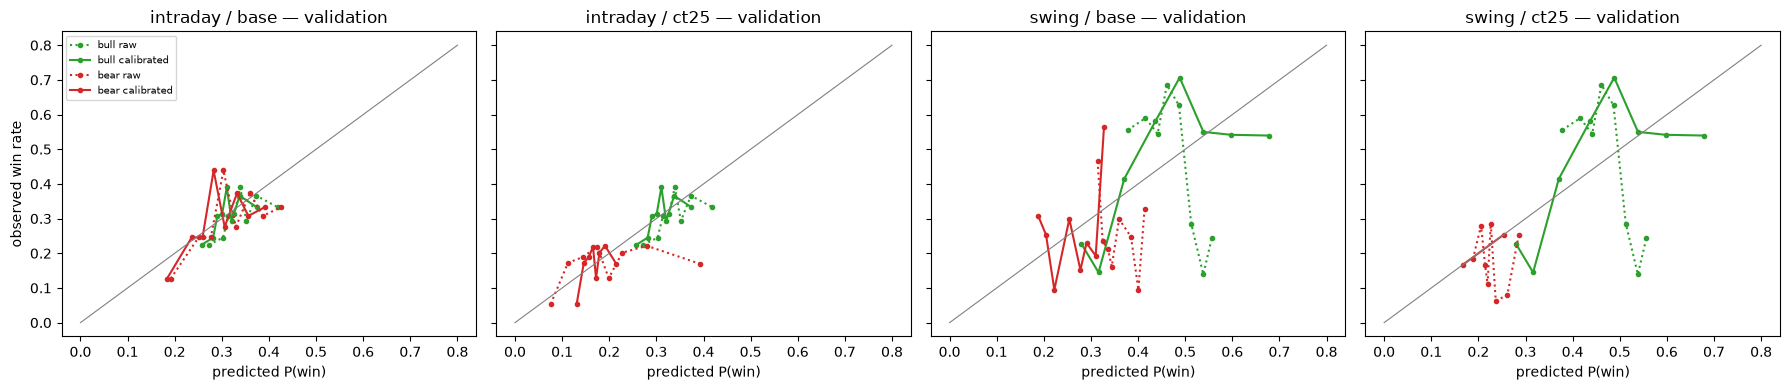

threshold             0.3000  0.3500  0.4000  0.4500  0.5000  0.5500  0.6000
horizon  labels side                                                        
intraday base   bear  0.3250  0.3186  0.3800     NaN     NaN     NaN     NaN
                bull  0.3434  0.3205     NaN     NaN     NaN     NaN     NaN
         ct25   bull  0.3434  0.3205     NaN     NaN     NaN     NaN     NaN
swing    base   bear  0.3630     NaN     NaN     NaN     NaN     NaN     NaN
                bull  0.5000  0.5558  0.5903  0.5872  0.5702  0.5754  0.5429
         ct25   bull  0.5000  0.5558  0.5903  0.5872  0.5702  0.5754  0.5429

In [12]:
# Calibration curves on validation (raw vs calibrated) + precision at thresholds (calibrated)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, key in zip(axes, LAB):
    va = LAB[key][MASKS[key]["val"]]
    for s, color in zip(SIDES, ("tab:green", "tab:red")):
        raw = FINAL[key]["boosters"][s].predict(va[FEATURES[key[0]]])
        for p, ls_, lab in ((raw, ":", "raw"), (FINAL[key]["p_val"][s], "-", "calibrated")):
            fp, mp = calibration_curve(va[f"y_{s}"], p, n_bins=8, strategy="quantile")
            ax.plot(mp, fp, ls_, color=color, marker="o", ms=3, label=f"{s} {lab}")
    ax.plot([0, 0.8], [0, 0.8], color="grey", lw=0.8)
    ax.set_title(f"{key[0]} / {key[1]} — validation")
    ax.set_xlabel("predicted P(win)")
axes[0].set_ylabel("observed win rate")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
prec = []
for key in LAB:
    va = LAB[key][MASKS[key]["val"]]
    for s in SIDES:
        t = M.precision_at(FINAL[key]["p_val"][s], va[f"y_{s}"].to_numpy())
        prec.append(t.assign(horizon=key[0], labels=key[1], side=s))
display(pd.concat(prec).pivot_table(index=["horizon", "labels", "side"], columns="threshold", values="precision"))

## 7. เลือก τ และ m บน validation เท่านั้น

กฎ: **long** เมื่อ P_bull ≥ τ และ P_bull − P_bear ≥ m · **short** กลับกัน · นอกนั้น flat
เกณฑ์เลือก: คะแนน Σr/√n (ให้น้ำหนักทั้ง edge และจำนวนเทรด) เฉพาะชุดที่มีเทรด ≥ `MIN_VAL_TRADES` และ PF > 1 — ถ้าไม่มีชุดไหนผ่าน config นั้นจะ **ไม่เทรด** (τ = 1.01) และรายงานตามนั้น
simulator ที่ใช้เลือกคือ replica ของ harness (`sim.py`, ใช้ outcome จาก label) แล้วยืนยันด้วย pybroker บน validation ด้วยโมเดลที่ freeze แล้ว

In [13]:
CHOICE, rows = {}, []
for key, fr in LAB.items():
    hz = C.HORIZONS[key[0]]
    rows_va = np.flatnonzero(MASKS[key]["val"])
    grid, best = S.select_tau_m(fr, rows_va, FINAL[key]["p_val"]["bull"], FINAL[key]["p_val"]["bear"],
                                C.TAU_GRID, C.MARGIN_GRID, C.MIN_VAL_TRADES[hz.tf])
    CHOICE[key] = {"tau": best["tau"], "m": best["m"], "no_trade": False} if best else {"tau": 1.01, "m": 0.0, "no_trade": True}
    top = grid.sort_values("score", ascending=False).head(3)
    rows.append({"horizon": key[0], "labels": key[1], **CHOICE[key],
                 "val_trades": best["trades"] if best else 0, "val_win_rate": best["win_rate"] if best else np.nan,
                 "val_pf": best["profit_factor"] if best else np.nan, "val_exp_r": best["expectancy_r"] if best else np.nan,
                 "val_long_share": best["long_share"] if best else np.nan,
                 "best_score_any": top["score"].iloc[0], "grid_cells_qualifying": int(((grid["trades"] >= C.MIN_VAL_TRADES[hz.tf]) & (grid["profit_factor"] > 1)).sum())})
display(pd.DataFrame(rows))

,horizon,labels,tau,m,no_trade,val_trades,val_win_rate,val_pf,val_exp_r,val_long_share,best_score_any,grid_cells_qualifying
0,intraday,base,1.0100,0.0000,True,0.0000,NaN,NaN,NaN,NaN,2.0433,0
1,intraday,ct25,0.3500,0.0000,False,55.0000,0.5091,1.0661,0.0342,1.0000,0.2540,4
2,swing,base,0.4500,0.2000,False,24.0000,0.6250,2.3766,0.5259,1.0000,2.5766,70
3,swing,ct25,0.4500,0.0000,False,26.0000,0.6154,2.2864,0.5037,1.0000,2.5686,70


**อ่านผล:** intraday/base ไม่มีชุด τ/m ไหนผ่าน (PF > 1 และ ≥ 40 เทรด) → ไม่เทรด; อีก 3 config ได้ชุดที่ออกมาเป็น long ล้วน — สะท้อน regime ขาขึ้นของ validation

In [14]:
# Confirm with pybroker on validation: frozen (pretrained) models, chosen tau/m
FROZEN = {}
for key, fr in LAB.items():
    hzn, lsn = key
    FROZEN[key] = {s: P.WFModel(FINAL[key]["boosters"][s], FINAL[key]["cals"][s], FEATURES[hzn]) for s in SIDES}


def pybroker_model_run(key, start, end):
    hzn, lsn = key
    hz, ls, fr = C.HORIZONS[hzn], C.LABEL_SETS[lsn], LAB[key]
    use_columns(htf_cols(hzn))
    names = {s: f"fz_{hzn}_{lsn}_{s}" for s in SIDES}
    srcs = [P.register_pretrained(names[s], INDS, FROZEN[key][s]) for s in SIDES]
    st = pyb.Strategy(P.pb_frame(fr, htf_cols(hzn)), C.WARMUP_START[hz.tf], end, P.config(hz.tf))
    st.add_execution(P.model_exec(hz, ls, names["bull"], names["bear"], CHOICE[key]["tau"], CHOICE[key]["m"]),
                     [C.SYMBOL], models=srcs, indicators=INDS)
    res, first = P.frozen_backtest(st, fr, start, end, hz.tf)
    assert first >= pd.Timestamp(start)
    return P.r_metrics(P.trades_in_r(res, fr), res)


VAL_TRADE = []
for key, fr in LAB.items():
    rows_va = np.flatnonzero(MASKS[key]["val"])
    va = fr.iloc[rows_va]
    sig = S.signals(FINAL[key]["p_val"]["bull"], FINAL[key]["p_val"]["bear"], CHOICE[key]["tau"], CHOICE[key]["m"])
    VAL_TRADE.append({"horizon": key[0], "labels": key[1], "engine": "replica (harness rules)", **S.metrics(S.run(fr, rows_va, sig))})
    if not CHOICE[key]["no_trade"]:
        VAL_TRADE.append({"horizon": key[0], "labels": key[1], "engine": "pybroker", **pybroker_model_run(key, va["date"].min(), C.VAL[1])})
display(pd.DataFrame(VAL_TRADE))

Backtesting: 2025-07-28 22:00:00 to 2025-09-30 23:59:00



Computing indicators...


Train split: 2025-07-28 22:15:00 to 2025-08-01 04:45:00


Finished training models: 0:00:00 



Test split: 2025-08-01 05:00:00 to 2025-09-12 23:45:00


...

Train split: 2025-07-17 03:00:00 to 2025-08-05 02:00:00

Finished training models: 0:00:00 



Test split: 2025-08-05 03:00:00 to 2025-09-12 23:00:00


Finished backtest: 0:00:00


,horizon,labels,engine,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,long_share,longs,shorts,return_pct
0,intraday,base,replica (harness rules),0,NaN,NaN,NaN,0.0000,0.0000,NaN,0,0,NaN
1,intraday,ct25,replica (harness rules),55,0.5091,1.0661,0.0342,1.8836,8.9926,1.0000,55,0,NaN
2,intraday,ct25,pybroker,54,0.5000,1.0903,0.0468,2.5276,9.1993,1.0000,54,0,2.1970
3,swing,base,replica (harness rules),24,0.6250,2.3766,0.5259,12.6225,3.0241,1.0000,24,0,NaN
4,swing,base,pybroker,24,0.6250,2.3766,0.5259,12.6225,3.8638,1.0000,24,0,13.2218
5,swing,ct25,replica (harness rules),26,0.6154,2.2864,0.5037,13.0973,3.0202,1.0000,26,0,NaN
6,swing,ct25,pybroker,26,0.6154,2.2864,0.5037,13.0973,3.8599,1.0000,26,0,13.7424


**อ่านผล:** pybroker กับ replica กติกา harness ให้ผลเกือบเท่ากัน (swing ตรงกันทุกตัว) — ยืนยันว่า label/simulator ทำตามกติการะบบจริง

## 8. บันทึกโมเดล (ก่อนเปิด test)

ต่อ config: `models/xau_<horizon>_<labels>.{bull,bear}.txt` (LightGBM text) + `.json` (feature list ตามลำดับ, timeframe, label params, ช่วง train/val/test, purge/embargo, calibrator เป็นตัวเลข, τ/m, metrics, version, sha ของไฟล์) — โหลดเป็น deterministic predictor ได้ด้วย `xau_ml/predictor.py` (ต้องการแค่ lightgbm + numpy + `features.py`)

In [15]:
FEATURE_CODE_SHA = hashlib.sha256((NB_DIR / "xau_ml" / "features.py").read_bytes()).hexdigest()[:16]
META_PATHS = {}
for key in LAB:
    hzn, lsn = key
    hz, ls = C.HORIZONS[hzn], C.LABEL_SETS[lsn]
    val_rows = VAL_ML.query("horizon == @hzn and labels == @lsn").set_index("side")
    meta = {
        "version": C.VERSION, "symbol": C.SYMBOL, "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "horizon": hzn, "timeframe": hz.tf, "context_timeframes": list(hz.htf),
        "label": {"type": "triple_barrier", "entry": "open of the next bar", "stop_r": 1.0, "risk": f"{hz.sl_atr} x ATR14 (Wilder) of the decision bar",
                  "tp_r": ls.tp_r, "counter_trend_tp_r": ls.ct_tp_r,
                  "counter_trend_rule": "last closed daily close on the trend side of both SMA50 and SMA200, against the trade",
                  "time_stop_bars": hz.time_stop, "time_stop_semantics": "bars held after the entry bar (engine.py bars_held); exit at close",
                  "intrabar_rule": "stop_first", "gap_rule": "open beyond a level exits at that open"},
        "features": FEATURES[hzn], "feature_code": {"module": "notebook/xau_ml/features.py", "sha256_16": FEATURE_CODE_SHA},
        "htf_merge": "merge_asof backward on bar close time <= decision bar close time",
        "splits": {"train": C.TRAIN, "validation": C.VAL, "test": C.TEST, "purge_bars": hz.time_stop + 1, "embargo_bars": hz.time_stop,
                   "warmup_from": C.WARMUP_START, "reserved_never_used": "2026-08-01 .. 2026-09-30"},
        "model": {"library": f"lightgbm {lgb.__version__}", "params": C.ModelParams().params,
                  "rounds": {s: FINAL[key]["boosters"][s].num_trees() for s in SIDES}, "scaler": "none (tree model)"},
        "signal_rule": {**CHOICE[key], "rule": "long if p_bull>=tau and p_bull-p_bear>=m; short mirrored; else flat",
                        "selected_on": "validation only"},
        "costs": {"round_trip_usd_per_oz": C.COST_PRICE, "risk_pct": C.RISK_PCT},
        "metrics": {"validation_ml": val_rows.drop(columns=["horizon", "labels"]).to_dict("index"),
                    "validation_trading": [r for r in VAL_TRADE if (r["horizon"], r["labels"]) == key],
                    "walkforward_pybroker": WF[key], "test": None},
    }
    META_PATHS[key] = PR.save(C.MODEL_DIR, f"xau_{hzn}_{lsn}", FINAL[key]["boosters"], FINAL[key]["cals"], meta)
    print("saved", META_PATHS[key].relative_to(NB_DIR))

saved models\xau_intraday_base.json


saved models\xau_intraday_ct25.json
saved models\xau_swing_base.json


saved

 models\xau_swing_ct25.json


## 9. TEST — เปิดครั้งเดียว

เซลล์ถัดไปเขียน `models/test_lock.json` เก็บ hash ของ (booster, calibrator, τ/m, features, splits) ถ้ารัน notebook ซ้ำด้วยสิ่งเหล่านี้ที่เปลี่ยนไป จะหยุดด้วย error — **ห้ามกลับไปจูนตามผล test** (รันซ้ำด้วย config เดิมได้ เพราะ deterministic)

> บันทึกความโปร่งใส: การรัน notebook อัตโนมัติครั้งแรก (2026-10-04) ไปถึงเซลล์ test และสร้าง lock แล้ว แต่ไม่มีการเปิดดูผล test — หลังจากนั้นพบ data hole 2 ช่วงจากผลตรวจข้อมูล (§1) จึงแก้ pipeline (ตัดแถวคร่อม hole) และลบ lock เดิมหนึ่งครั้ง การเปลี่ยนนี้มาจาก audit ไม่ได้มาจากผล test

re-run of the same frozen config 16a70a7e6bc9bc4bbda2a0bf (test first opened 2026-10-04T08:37:29+00:00)


,horizon,labels,side,rows,base_rate,mean_pred,auc,brier,brier_climatology(train rate)
0,intraday,base,bull,5838,0.3164,0.2925,0.5628,0.2153,0.2165
1,intraday,base,bear,5838,0.3123,0.3205,0.5991,0.2094,0.2148
2,intraday,ct25,bull,5838,0.3164,0.2925,0.5628,0.2153,0.2165
3,intraday,ct25,bear,5838,0.1542,0.1737,0.6148,0.1288,0.1310
4,swing,base,bull,1178,0.4643,0.6196,0.4650,0.2944,0.2491
5,swing,base,bear,1178,0.2818,0.2391,0.4707,0.2128,0.2084
6,swing,ct25,bull,1178,0.4643,0.6196,0.4650,0.2944,0.2491
7,swing,ct25,bear,1178,0.0806,0.1070,0.6970,0.0744,0.0911


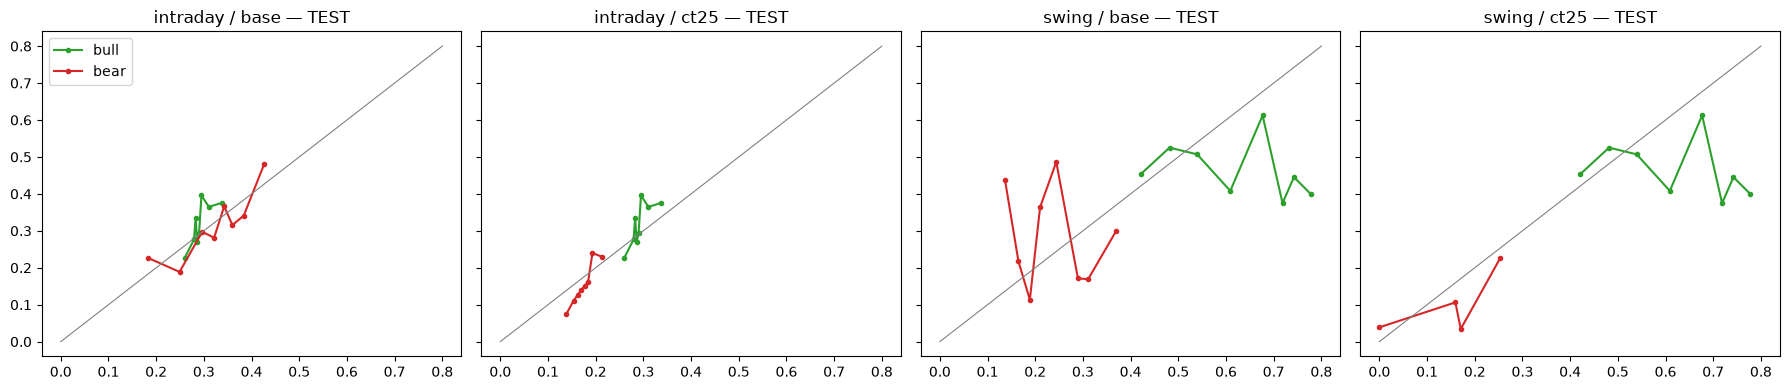

In [16]:
def config_fingerprint() -> str:
    h = hashlib.sha256()
    for key in sorted(LAB):
        for s in SIDES:
            h.update(FINAL[key]["boosters"][s].model_to_string().encode())
            h.update(json.dumps(FINAL[key]["cals"][s].to_json(), sort_keys=True).encode())
        h.update(json.dumps([CHOICE[key], FEATURES[key[0]], C.TRAIN, C.VAL, C.TEST], sort_keys=True, default=str).encode())
    return h.hexdigest()[:24]


LOCK = C.MODEL_DIR / "test_lock.json"
fp = config_fingerprint()
if LOCK.exists():
    lock = json.loads(LOCK.read_text())
    if lock["fingerprint"] != fp:
        raise RuntimeError(f"test was already opened on {lock['opened_utc']} with config {lock['fingerprint']}; "
                           f"this run is {fp}. Changing models/tau/m after seeing test is not allowed.")
    print(f"re-run of the same frozen config {fp} (test first opened {lock['opened_utc']})")
else:
    LOCK.write_text(json.dumps({"fingerprint": fp, "opened_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}, indent=2))
    print(f"test opened for the first time with config {fp}")

TEST_ML, P_TEST = [], {}
for key, fr in LAB.items():
    te = fr[MASKS[key]["test"]].reset_index(drop=True)
    P_TEST[key] = {s: FROZEN[key][s].predict(te) for s in SIDES}
    for s in SIDES:
        y = te[f"y_{s}"].to_numpy()
        p = P_TEST[key][s]
        TEST_ML.append({"horizon": key[0], "labels": key[1], "side": s, "rows": len(y), "base_rate": y.mean(),
                        "mean_pred": p.mean(), "auc": roc_auc_score(y, p), "brier": brier_score_loss(y, p),
                        "brier_climatology(train rate)": brier_score_loss(y, np.full(len(y), LAB[key][MASKS[key]["train"]][f"y_{s}"].mean()))})
TEST_ML = pd.DataFrame(TEST_ML)
display(TEST_ML)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, key in zip(axes, LAB):
    te = LAB[key][MASKS[key]["test"]]
    for s, color in zip(SIDES, ("tab:green", "tab:red")):
        fp_, mp_ = calibration_curve(te[f"y_{s}"], P_TEST[key][s], n_bins=8, strategy="quantile")
        ax.plot(mp_, fp_, "-o", color=color, ms=3, label=s)
    ax.plot([0, 0.8], [0, 0.8], color="grey", lw=0.8)
    ax.set_title(f"{key[0]} / {key[1]} — TEST")
axes[0].legend()
plt.tight_layout()
plt.show()

**อ่านผล:** intraday มี skill อ่อน (AUC 0.56–0.61, Brier ดีกว่า climatology เล็กน้อย); swing bull/bear AUC 0.47 = ไม่มี skill และ Brier แย่กว่า climatology

In [17]:
# Trading on TEST: model (replica + pybroker) vs baselines, same exits and costs
def baseline_signals(fr_split, kind):
    n = len(fr_split)
    if kind == "always_short":
        return np.full(n, -1, dtype="int8")
    if kind == "always_long":
        return np.full(n, 1, dtype="int8")
    s20, s50 = fr_split["sma20"].to_numpy(), fr_split["sma50"].to_numpy()
    up = (s20 > s50) & (np.r_[np.nan, s20[:-1]] <= np.r_[np.nan, s50[:-1]])
    dn = (s20 < s50) & (np.r_[np.nan, s20[:-1]] >= np.r_[np.nan, s50[:-1]])
    return np.where(up, 1, np.where(dn, -1, 0)).astype("int8")


def pybroker_baseline(key, kind, start, end):
    hzn, lsn = key
    hz, ls, fr = C.HORIZONS[hzn], C.LABEL_SETS[lsn], LAB[key]
    use_columns(htf_cols(hzn))
    fn = {"always_short": P.always_exec(-1, hz, ls), "always_long": P.always_exec(1, hz, ls),
          "sma20_50_cross": P.sma_cross_exec(hz, ls), "buy_and_hold": P.buy_hold_exec}[kind]
    st = pyb.Strategy(P.pb_frame(fr, htf_cols(hzn)), C.WARMUP_START[hz.tf], end, P.config(hz.tf))
    st.add_execution(fn, [C.SYMBOL], indicators=INDS + SMA_INDS)
    res = st.backtest(start_date=start, end_date=end, timeframe=hz.tf)
    return P.r_metrics(P.trades_in_r(res, fr), res)


TEST_TRADE, TEST_TRADES = [], {}
for key, fr in LAB.items():
    rows_te = np.flatnonzero(MASKS[key]["test"])
    te = fr.iloc[rows_te].reset_index(drop=True)
    closes = fr["close"].to_numpy()
    sma20, sma50 = pd.Series(F.sma(closes, 20), index=fr["date"]), pd.Series(F.sma(closes, 50), index=fr["date"])
    te["sma20"], te["sma50"] = sma20.loc[te["date"]].to_numpy(), sma50.loc[te["date"]].to_numpy()
    start, end = te["date"].min(), C.TEST[1]
    sig = S.signals(P_TEST[key]["bull"], P_TEST[key]["bear"], CHOICE[key]["tau"], CHOICE[key]["m"])
    TEST_TRADES[key] = S.run(fr, rows_te, sig)
    TEST_TRADE.append({"horizon": key[0], "labels": key[1], "strategy": "ML bull/bear", "engine": "replica", **S.metrics(TEST_TRADES[key])})
    if not CHOICE[key]["no_trade"]:
        TEST_TRADE.append({"horizon": key[0], "labels": key[1], "strategy": "ML bull/bear", "engine": "pybroker", **pybroker_model_run(key, start, end)})
    for kind in ("always_short", "always_long", "sma20_50_cross"):
        TEST_TRADE.append({"horizon": key[0], "labels": key[1], "strategy": kind, "engine": "replica", **S.metrics(S.run(fr, rows_te, baseline_signals(te, kind)))})
        TEST_TRADE.append({"horizon": key[0], "labels": key[1], "strategy": kind, "engine": "pybroker", **pybroker_baseline(key, kind, start, end)})
    if key[1] == "base":
        TEST_TRADE.append({"horizon": key[0], "labels": "-", "strategy": "buy_and_hold", "engine": "pybroker", **pybroker_baseline(key, "buy_and_hold", start, end)})
TEST_TRADE = pd.DataFrame(TEST_TRADE)
cols_show = ["horizon", "labels", "strategy", "engine", "trades", "win_rate", "profit_factor", "expectancy_r", "total_r", "max_dd_pct", "return_pct", "long_share", "longs", "shorts"]
display(TEST_TRADE.reindex(columns=cols_show))

Backtesting: 2025-10-17 11:45:00 to 2026-01-30 23:59:00



Computing indicators...


Test split: 2025-10-17 11:45:00 to 2026-01-30 23:45:00


Finished backtest: 0:00:01


Backtesting: 2025-10-17 11:45:00 to 2026-01-30 23:59:00



...

Backtesting: 2025-10-27 22:00:00 to 2026-01-30 23:59:00


Computing indicators...


Test split: 2025-10-27 22:00:00 to 2026-01-30 23:00:00

Finished backtest: 0:00:00


,horizon,labels,strategy,engine,trades,win_rate,profit_factor,expectancy_r,total_r,max_dd_pct,return_pct,long_share,longs,shorts
0,intraday,base,ML bull/bear,replica,0,NaN,NaN,NaN,0.0000,0.0000,NaN,NaN,0,0
1,intraday,base,always_short,replica,759,0.3939,0.8524,-0.0854,-64.7884,65.7698,NaN,0.0000,0,759
2,intraday,base,always_short,pybroker,735,0.3918,0.8402,-0.0932,-68.5183,65.6068,-51.8547,0.0000,0,735
3,intraday,base,always_long,replica,716,0.4525,1.0633,0.0336,24.0504,25.9819,NaN,1.0000,716,0
4,intraday,base,always_long,pybroker,698,0.4599,1.0865,0.0457,31.9229,25.9404,31.0882,1.0000,698,0
5,intraday,base,sma20_50_cross,replica,117,0.4444,0.9873,-0.0068,-0.7998,11.4846,NaN,0.4957,58,59
6,intraday,base,sma20_50_cross,pybroker,116,0.4397,0.9671,-0.0178,-2.0606,11.6174,-2.7587,0.5000,58,58
7,intraday,-,buy_and_hold,pybroker,1,1.0000,inf,20.9688,20.9688,15.1178,12.4611,1.0000,1,0
8,intraday,ct25,ML bull/bear,replica,16,0.5000,1.3874,0.1903,3.0447,2.0520,NaN,1.0000,16,0
9,intraday,ct25,ML bull/bear,pybroker,16,0.5000,1.2932,0.1545,2.4723,2.9525,2.3779,1.0000,16,0


**อ่านผล:** โมเดลผ่าน PF > 1 แต่ทุกตัว long 100% และ **แพ้ always-long / buy & hold** — always-short แย่ที่สุดทุก horizon ซึ่งอธิบายผลขาดทุนของระบบ LLM ที่ short เกือบตลอด

expectancy_r                      profit_factor                     
cost_usd_oz           0.0000 0.1500 0.3000 0.5000        0.0000 0.1500 0.3000 0.5000
horizon  labels                                                                     
intraday ct25         0.2142 0.2023 0.1903 0.1743        1.4469 1.4168 1.3874 1.3493
swing    base         0.0737 0.0690 0.0644 0.0582        1.1349 1.1258 1.1167 1.1048
         ct25         0.1555 0.1509 0.1462 0.1400        1.3018 1.2913 1.2809 1.2673

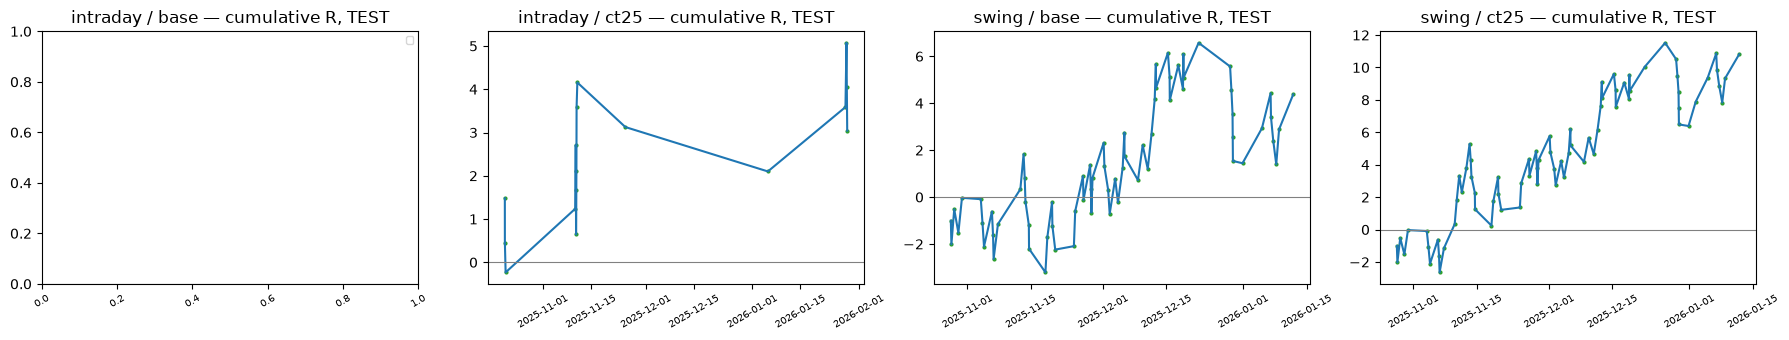

intraday/ct25         swing/base         swing/ct25        
                count     sum      count     sum      count     sum
entry                                                              
2025-10        3.0000 -0.2323          6 -0.0890          6 -0.0890
2025-11        8.0000  3.3590         26  2.4060         30  5.8615
2026-01        5.0000 -0.0820          7  2.9355          7  2.9356
2025-12           NaN     NaN         29 -0.8748         31  2.1106

In [18]:
# Cost sensitivity (reporting only — nothing is re-chosen) and equity in R on TEST
rows = []
for key, fr in LAB.items():
    rows_te = np.flatnonzero(MASKS[key]["test"])
    sig = S.signals(P_TEST[key]["bull"], P_TEST[key]["bear"], CHOICE[key]["tau"], CHOICE[key]["m"])
    for cost in (0.0, 0.15, 0.30, 0.50):
        mt = S.metrics(S.run(fr, rows_te, sig, cost_price=cost))
        rows.append({"horizon": key[0], "labels": key[1], "cost_usd_oz": cost, **{k: mt[k] for k in ("trades", "win_rate", "profit_factor", "expectancy_r")}})
display(pd.DataFrame(rows).pivot_table(index=["horizon", "labels"], columns="cost_usd_oz", values=["profit_factor", "expectancy_r"]))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, key in zip(axes, LAB):
    t = TEST_TRADES[key]
    if len(t):
        ax.plot(t["exit"], t["r"].cumsum(), label="ML (net R)")
        for side, c in (("long", "tab:green"), ("short", "tab:red")):
            ts = t[t["side"] == side]
            ax.scatter(ts["exit"], t["r"].cumsum()[ts.index], s=4, color=c, label=side)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{key[0]} / {key[1]} — cumulative R, TEST")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
monthly = pd.concat({f"{k[0]}/{k[1]}": t.groupby(pd.to_datetime(t["entry"]).dt.to_period("M"))["r"].agg(["count", "sum"]) for k, t in TEST_TRADES.items() if len(t)}, axis=1)
display(monthly)

**อ่านผล:** config ที่เลือกเทรดน้อยและ R กว้าง จึงแทบไม่ไวต่อต้นทุน; กำไรกระจุกใน 2025-11 (เดือนเดียว) → ผลเปราะ

## 10. Feature สำคัญ (SHAP บน test)

ใช้ `shap.TreeExplainer` กับ booster ดิบ (ก่อน calibrate — calibrator เป็น monotone จึงไม่เปลี่ยนลำดับความสำคัญ) — ค่าเฉลี่ย |SHAP| สูงสุด 12 ตัวต่อโมเดล ของ label set `base`

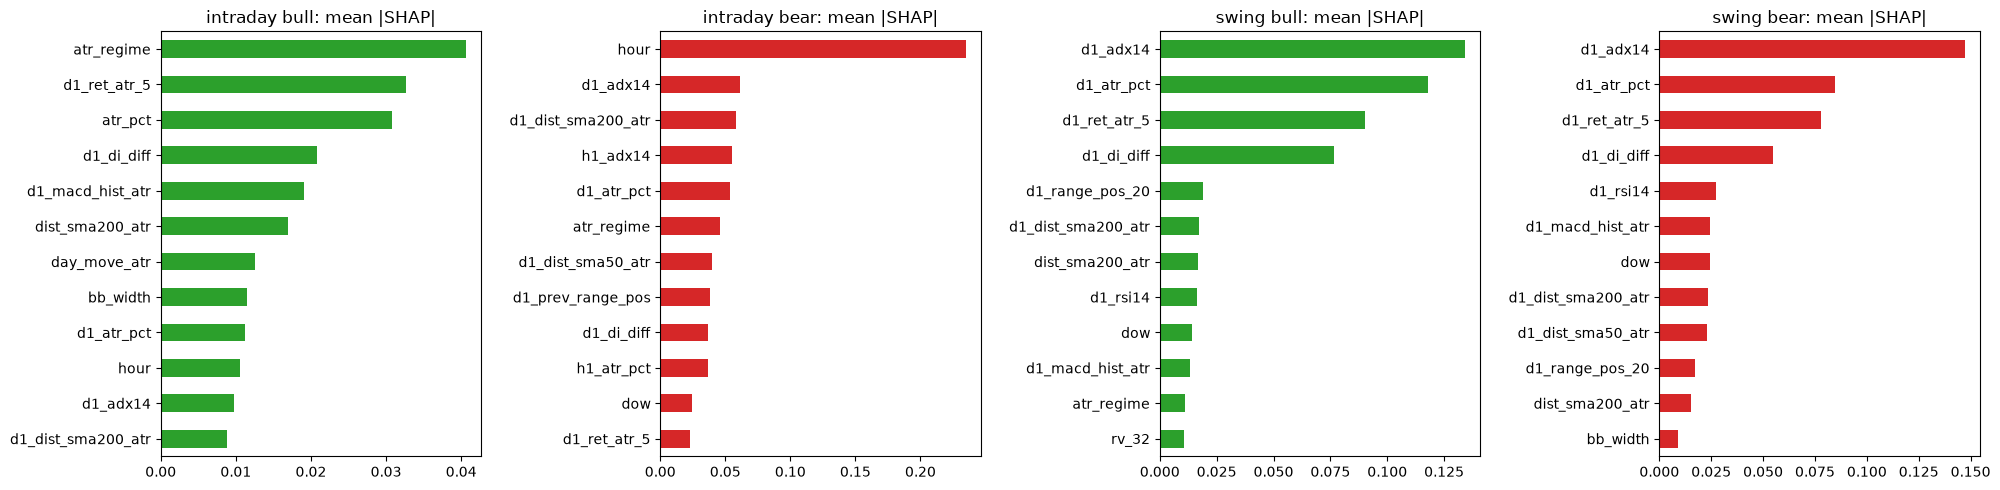

,intraday bull,intraday bear,swing bull,swing bear
0,atr_regime,hour,d1_adx14,d1_adx14
1,d1_ret_atr_5,d1_adx14,d1_atr_pct,d1_atr_pct
2,atr_pct,d1_dist_sma200_atr,d1_ret_atr_5,d1_ret_atr_5
3,d1_di_diff,h1_adx14,d1_di_diff,d1_di_diff
4,d1_macd_hist_atr,d1_atr_pct,d1_range_pos_20,d1_rsi14
5,dist_sma200_atr,atr_regime,d1_dist_sma200_atr,d1_macd_hist_atr
6,day_move_atr,d1_dist_sma50_atr,dist_sma200_atr,dow
7,bb_width,d1_prev_range_pos,d1_rsi14,d1_dist_sma200_atr
8,d1_atr_pct,d1_di_diff,dow,d1_dist_sma50_atr
9,hour,h1_atr_pct,d1_macd_hist_atr,d1_range_pos_20


In [19]:
IMPORTANCE = {}
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
i = 0
for key in [k for k in LAB if k[1] == "base"]:
    te = LAB[key][MASKS[key]["test"]]
    X = te[FEATURES[key[0]]].sample(min(3000, len(te)), random_state=SEED)
    for s in SIDES:
        sv = shap.TreeExplainer(FINAL[key]["boosters"][s]).shap_values(X)
        sv = sv[1] if isinstance(sv, list) else sv
        imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
        IMPORTANCE[(key[0], s)] = imp
        imp.head(12)[::-1].plot.barh(ax=axes[i], color="tab:green" if s == "bull" else "tab:red")
        axes[i].set_title(f"{key[0]} {s}: mean |SHAP|")
        i += 1
plt.tight_layout()
plt.show()
display(pd.DataFrame({f"{h} {s}": imp.head(10).index for (h, s), imp in IMPORTANCE.items()}))

**อ่านผล:** feature บนสุดเป็นบริบทรายวัน/ความผันผวน (`d1_adx14`, `d1_atr_pct`, `atr_regime`) และ `hour` — โมเดลจับ regime ไม่ใช่จังหวะเข้า

## 11. Deterministic predictor: โหลดจากไฟล์ → คำนวณจากแท่งดิบ → ต้องได้ผลเท่าเดิม

ทดสอบเส้นทางที่ backend จะใช้: `Predictor.load(json)` → `from_bars(แท่งหลัก, แท่ง HTF)` (สร้าง feature เองจากราคา) → ความน่าจะเป็นต้องตรงกับใน notebook และบันทึกผล test ลง metadata

In [20]:
for key, path in META_PATHS.items():
    pred = PR.Predictor.load(path)
    hz = C.HORIZONS[key[0]]
    end = pd.Timestamp(C.TEST[1])
    main = RAW[hz.tf][RAW[hz.tf]["date"] <= end]
    out = pred.from_bars(main, {tf: RAW[tf] for tf in hz.htf}).set_index("date")
    te = LAB[key][MASKS[key]["test"]]
    for s in SIDES:
        np.testing.assert_allclose(out.loc[te["date"], f"p_{s}"].to_numpy(), P_TEST[key][s], rtol=0, atol=1e-12)
    meta = json.loads(path.read_text(encoding="utf-8"))
    meta["metrics"]["test"] = {
        "ml": TEST_ML.query("horizon == @key[0] and labels == @key[1]").drop(columns=["horizon", "labels"]).to_dict("records"),
        "trading": TEST_TRADE.query("horizon == @key[0] and labels == @key[1]").drop(columns=["horizon", "labels"]).to_dict("records"),
        "test_lock": fp,
    }
    path.write_text(json.dumps(meta, indent=2, default=str), encoding="utf-8")
    print(f"{path.name}: reload + rebuild from bars == notebook ✓; test metrics written")

xau_intraday_base.json: reload + rebuild from bars == notebook ✓; test metrics written


xau_intraday_ct25.json: reload + rebuild from bars == notebook ✓; test metrics written


xau_swing_base.json: reload + rebuild from bars == notebook ✓; test metrics written


xau_swing_ct25.json: reload + rebuild from bars == notebook ✓; test metrics written


**อ่านผล:** โหลดโมเดลจากไฟล์แล้วคำนวณจากแท่งราคาดิบได้ความน่าจะเป็นเท่ากับใน notebook ทุกแถว → พร้อมให้ backend ใช้เป็น deterministic predictor

In [21]:
# Results table for the summary
summary = TEST_TRADE.query("strategy == 'ML bull/bear'").merge(pd.DataFrame([{"horizon": k[0], "labels": k[1], **v} for k, v in CHOICE.items()]), on=["horizon", "labels"])
display(summary.reindex(columns=["horizon", "labels", "engine", "tau", "m", "no_trade", "trades", "win_rate", "profit_factor", "expectancy_r", "max_dd_pct", "long_share"]))
display(TEST_ML.pivot_table(index=["horizon", "labels"], columns="side", values=["auc", "brier", "brier_climatology(train rate)"]))

,horizon,labels,engine,tau,m,no_trade,trades,win_rate,profit_factor,expectancy_r,max_dd_pct,long_share
0,intraday,base,replica,1.0100,0.0000,True,0,NaN,NaN,NaN,0.0000,NaN
1,intraday,ct25,replica,0.3500,0.0000,False,16,0.5000,1.3874,0.1903,2.0520,1.0000
2,intraday,ct25,pybroker,0.3500,0.0000,False,16,0.5000,1.2932,0.1545,2.9525,1.0000
3,swing,base,replica,0.4500,0.2000,False,68,0.4265,1.1167,0.0644,5.1060,1.0000
4,swing,base,pybroker,0.4500,0.2000,False,66,0.4394,1.1501,0.0828,5.2641,1.0000
5,swing,ct25,replica,0.4500,0.0000,False,74,0.4595,1.2809,0.1462,5.0271,1.0000
6,swing,ct25,pybroker,0.4500,0.0000,False,72,0.4722,1.3182,0.1654,5.2641,1.0000


auc         brier        brier_climatology(train rate)       
side              bear   bull   bear   bull                          bear   bull
horizon  labels                                                                 
intraday base   0.5991 0.5628 0.2094 0.2153                        0.2148 0.2165
         ct25   0.6148 0.5628 0.1288 0.2153                        0.1310 0.2165
swing    base   0.4707 0.4650 0.2128 0.2944                        0.2084 0.2491
         ct25   0.6970 0.4650 0.0744 0.2944                        0.0911 0.2491

## Results (test 2025-10-17 → 2026-01-30, เปิดดูครั้งเดียว)

**สรุปสั้น:** ผ่านเป้า "win rate 40–50% และ PF > 1" **ตามตัวเลข** ใน 3 จาก 4 config แต่ **ยังไม่มีหลักฐานว่าโมเดลเก่งกว่าการถือ long เฉยๆ** เพราะทุก config ที่เทรดเป็น long 100% และแพ้ baseline always-long / buy & hold

| config | τ / m | trades | win rate | PF | expectancy | max DD | long |
|---|---|---|---|---|---|---|---|
| intraday / base | ไม่เทรด (ไม่มีชุดไหนผ่านบน validation) | 0 | – | – | – | – | – |
| intraday / ct25 | 0.35 / 0 | 16 | 50% | 1.39 (pybroker 1.29) | +0.19R | 2.1% | 100% |
| swing / base | 0.45 / 0.20 | 68 | 42.6% | 1.12 (pybroker 1.15) | +0.06R | 5.1% | 100% |
| swing / ct25 | 0.45 / 0 | 74 | 46.0% | 1.28 (pybroker 1.32) | +0.15R | 5.0% | 100% |
| baseline always-long (swing) | – | 81 | 48.1% | 1.37 | +0.18R | 5.5% | 100% |
| baseline always-short (swing / intraday) | – | 88 / 759 | 33% / 39% | 0.66 / 0.85 | −0.23R / −0.09R | 20% / 66% | 0% |
| baseline SMA20/50 cross (swing) | – | 20 | 55% | 1.81 | +0.37R | 3.0% | 50% |
| buy & hold | – | – | – | – | +22.7% (swing) / +12.5% (intraday) | 13–15% | – |

**ผลด้าน ML (test):**
- intraday: AUC bull 0.56 · **bear 0.60** (ct25 bear 0.61) · Brier ดีกว่า climatology เล็กน้อย → มีความสามารถแยกแยะจริงแต่อ่อน
- swing: AUC bull 0.47 · bear 0.47 (**ต่ำกว่า 0.5 = ไม่มี skill**) ยกเว้น ct25 bear 0.70 แต่ base rate แค่ 8%
- walk-forward ใน pybroker (train+val, τ=0.45 ตั้งไว้ก่อน): OOS AUC bull ≈ 0.50 / bear ≈ 0.57 (intraday) และ PF < 1 ในทุก config ยกเว้น swing/ct25 (1.14)
- overfit ชัด: AUC train 0.73–0.89 แต่ validation 0.55–0.58 (swing < 0.5)

**long/short:** โมเดลไม่ได้สมดุลกว่าระบบ LLM แต่เอียงไปฝั่งตรงข้าม คือ long 100% เพราะปี 2025 ทองอยู่เหนือ SMA50 และ SMA200 รายวัน **91% ของเวลา** (ไม่มีวันไหนอยู่ใต้ทั้งคู่เลย) ข้อมูลที่ชัดที่สุดของงานนี้คือ **always-short แย่ที่สุดในทุก horizon** (intraday −65R, swing −20R บน test) → การที่ระบบ LLM short เกือบตลอดคือการเทรดสวนเทรนด์รายวันแทบทุกไม้ ซึ่งสอดคล้องกับ policy `counter_trend_risk_reward` ที่เพิ่งเพิ่ม

**ต้นทุน:** PF ของ config ที่เลือกแทบไม่เปลี่ยนเมื่อต้นทุน 0 → 0.50 USD/oz (เทรดน้อยและ R กว้าง) แต่ใน walk-forward intraday ที่เทรดถี่ ต้นทุน ~0.05R/ไม้กินกำไรหมด

**Feature สำคัญ (SHAP):** ถูกครอบงำด้วย **บริบทรายวันและ regime ความผันผวน** — `d1_adx14`, `d1_atr_pct`, `d1_ret_atr_5`, `d1_di_diff`, `atr_regime`, `hour` — ไม่ใช่สัญญาณจังหวะเข้า (RSI/BB/MACD ของแท่งหลักอยู่ท้าย) แปลว่าโมเดลเรียนรู้ว่า "ตอนนี้ตลาดเป็น regime แบบไหน" มากกว่า "ตรงนี้เข้าดีไหม"

**ตัวเลขที่ต้องระวัง / จุดอ่อน:**
1. ข้อมูลทั้งหมด ~13 เดือนใน regime เดียว (ทองขึ้นแรง) — test เป็นขาขึ้นต่อ จึงรางวัลการถือ long; ผลจะไม่ generalize ไปตลาดขาลง/sideway
2. ข้อมูลหาย 2 ช่วง (32 วัน และ 9 วัน) ทำให้ validation สั้น (swing 614 แถว ≈ 13 หน้าต่าง 48 แท่งที่ไม่ทับกัน) และ test จริงแค่ ~3.5 เดือน
3. intraday/ct25 มีแค่ **16 เทรด** — ค่าคลาดเคลื่อนของ expectancy ≈ ±0.3R จึงสรุปอะไรไม่ได้
4. τ/m ที่เลือกบน validation เล็กๆ ออกมาเป็น "long-only" — เป็นการเลือกตาม regime ของ validation มากกว่า skill ของโมเดล
5. label ทับกันมาก (หน้าต่าง 16/48 แท่ง) ทำให้ AUC ของ train สูงเกินจริงและ early stopping หยุดเร็ว (20 รอบ)
6. pybroker ไม่เช็ค stop ในแท่งที่เข้า ส่วน harness เช็ค — ผลจึงต่างกันเล็กน้อย (ดูคู่ replica/pybroker ซึ่งใกล้กันมาก)
7. ความโปร่งใส: lock ของ test ถูกลบหนึ่งครั้งก่อนเปิดดูผล เพราะพบ data hole จาก audit (ดู §9)

**ข้อเสนอ: ต่อเข้า harness เป็น "หลักฐานให้ analyst" ไม่ใช่ policy gate**
- **ไม่ควรเป็น policy gate (block):** gate ต้องเชื่อถือได้ระดับ deterministic rule แต่ skill ของโมเดลยังไม่ชัด (swing AUC < 0.5, ชนะ baseline ไม่ได้) ถ้าใช้ block จะกลายเป็นกฎ "ห้าม short ในขาขึ้น" ซึ่งทำได้ตรงกว่าด้วย rule `counter_trend_risk_reward` ที่มีอยู่แล้ว
- **ใช้เป็นหลักฐาน (evidence tool):** ให้ deterministic predictor (`xau_ml/predictor.py`, ตาม F1) คืน `P_bull`, `P_bear`, base rate, และ break-even ของ R:R ที่เสนอ พร้อม provenance (`kind=compute`, version, sha ของโมเดล) ให้ trader/risk analyst อ่าน — โดยเฉพาะ **P_bear ของ intraday (AUC 0.60)** เป็นคำเตือนเมื่อ LLM จะ short ทั้งที่ P(short ชนะ) ต่ำกว่า break-even
- ถ้าจะเป็น policy ให้เป็นระดับ **warn** เท่านั้น (เช่น "ML P(win) < break-even ของ R:R ที่เสนอ") จนกว่าจะผ่าน backtest Aug–Sep 2026 ผ่าน API ของ harness


## Next steps

- เทียบกับระบบจริง: รัน backtest API ของ harness ช่วง **Aug–Sep 2026** (ที่เก็บไว้) โดยใช้ ML เป็น evidence เทียบกับไม่ใช้ — วัดว่าลดการ short สวนเทรนด์ที่แพ้ได้ไหม
- หาข้อมูลเพิ่มที่ **ไม่ใช่** Aug–Sep 2026 (เช่น Feb–Jul 2026) และอุดช่องข้อมูลที่หาย (2025-09-12 → 10-15, 2026-01-13 → 01-22) เพื่อให้ validation/test ใหญ่พอและมี regime ขาลง/sideway
- ลอง **meta-labeling**: ใช้โมเดลกรองข้อเสนอของ LLM trader (label = ข้อเสนอของระบบชนะไหม) แทนการเดาทิศเอง — ตรงกับโจทย์ "ลดการ short ผิดฝั่ง" มากกว่า
- ลดความซับซ้อน: ชุด feature บริบทรายวัน + volatility regime (ที่ SHAP บอกว่าสำคัญ) และ regularize เพิ่ม (label ทับกัน → ใช้ sample weight ตาม uniqueness แบบ López de Prado)
- ทุกครั้งเทียบกับ **always-long / buy & hold** ไม่ใช่แค่ PF > 1 — ในตลาดขาขึ้น PF > 1 ได้ง่ายโดยไม่มี skill